# Kalman AI — the first AI-controlled application

This is the first application built on the **control contract** introduced in §8 of
`00_Kalman101.ipynb`: a controller is just a callable `(x̂, P, t, ν) → u`, and the `KalmanFilter`
never knows what's behind it — a fixed gain, a PID, an optimal LQR solve, or a trained neural network.

A Kalman filter **estimates** the hidden state of a system from noisy measurements.  But estimation alone
does not *change* the system — it only watches.  **Control** closes the loop: a controller reads the
filter's state estimate $\hat{x}$ and computes a control input $u$ that steers the system toward a
reference $x_{\mathrm{ref}}$.

This notebook demonstrates the framework's **pluggable control layer** — from a one-line proportional
gain to a neural policy trained offline via MPPI on the model's own physics — and, separately, the
**pluggable IMM routing layer**. Both are optional add-ons around a classical, unmodified Kalman core.

### Where does AI actually help — and where doesn't it?

It's easy to sprinkle "neural" onto every module in this framework. It's more useful to be precise
about *which* classical assumption each one breaks, because that's the only thing that tells you
whether a learned version is worth the training cost:

| Layer | Classical answer | Its assumption | Where AI genuinely helps | Shown in |
|---|---|---|---|---|
| **Control** ($u$) | `LQRKalmanController` — optimal via DARE | Linear dynamics, quadratic cost, **no active constraints** | Hard actuator limits / nonlinearities LQR's fixed gain can't see | §5–5c |
| **Regime routing** (IMM) | `BayesianRouter` — optimal Bayes update | Innovations are **truly Gaussian** | Heavy-tailed / non-Gaussian noise, where the Gaussian likelihood ratio is itself miscalibrated | §9–10b |
| **Noise-level adaptation** (Q, R) | `AdaptiveQRKalmanController`, `BoostKalmanController` | A simple scalar/window heuristic tracks the regime change well enough | Fast, structured, high-dimensional noise shifts a scalar rule can't track | §6–7 (flagged, not solved here) |

Two rows get a genuine, numbers-backed demonstration below. The third is included deliberately
because it's the one most often *mislabelled* as AI: `AdaptiveQRKalmanController` and
`BoostKalmanController` are plain innovation-driven heuristics — no training, no network — and
§6–7 say so before showing why that's already enough for a rapid, single-parameter noise-level jump.

### Architecture

```
filter.forward(zk, uk=controller)

  each step k:
  ┌─────────────────────────────────────────────────────────┐
  │ 1. u_k = controller(x̂_k, P_k, t_k, nu=ν_{k-1})       │  ← callable
  │ 2. engine._predict(model, x, P, u=u_k, t=t_k)          │  ← x⁻ = f(x) + B·u
  │ 3. engine._update(model, x, P, z_k, t=t_k)             │  ← classical Kalman gain
  └─────────────────────────────────────────────────────────┘
```

**Key design principle:** the `KalmanFilter` has zero knowledge of `KalmanController`.  The filter
only sees `uk` as a callable `(x̂, P, t, ν) → u`.  All estimation machinery (F, H, K, gain
computation) stays classical and untouched.

**Genuine closed loop:** every controller demo below drives a *true* simulated trajectory with the
*exact* `u` the controller computed from the filter's estimate — not an open-loop placeholder. See
`closed_loop_run()` after §1.

### Two kinds of Q and R

| Symbol | Meaning | Owned by |
|--------|---------|----------|
| Qnoise, Rnoise | Kalman filter noise covariances | model |
| Qcost, Rcost | Controller cost weights (penalise error vs effort) | controller |


In [1]:
%pip install numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt

import kalman; kalman.set_debug(0)
from kalman.filters import ExtendedKalmanFilter
from kalman.apps.vehicles import CarLaneModel
from kalman.framework import (
    ProportionalKalmanController,
    PIDKalmanController,
    LQRKalmanController,
    MPPIKalmanController,
    NeuralKalmanController,
    BoostKalmanController,
    AdaptiveQRKalmanController,
    NeuralAdaptiveQRKalmanController,
)



[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 1 — The test system: lateral lane-keeping

A car drives at constant speed $v$ along a lane.  Its state is:

$$\mathbf{x} = \begin{bmatrix} y \\ \psi \\ v \end{bmatrix}$$

where $y$ is the lateral offset from lane centre [m], $\psi$ is the heading angle [rad], and $v$ is
the longitudinal speed [m/s].  The single control input $u = [\delta]$ is the **steering angle** [rad].

Bicycle kinematics (Euler-discretised):

$$y_{k+1} = y_k + v_k \sin\psi_k \, \Delta t, \qquad
  \psi_{k+1} = \psi_k + \frac{v_k \tan\delta_k}{L} \Delta t, \qquad
  v_{k+1} = v_k$$

A noisy GPS measures lateral position only: $z = y + \text{noise}$.

The goal: steer $y \to 0$ (lane centre) from an initial offset.

State dim n=3, Measurement dim m=1, Control dim l=1
Initial state: y=1.5 m, ψ=0.10 rad, v=15 m/s


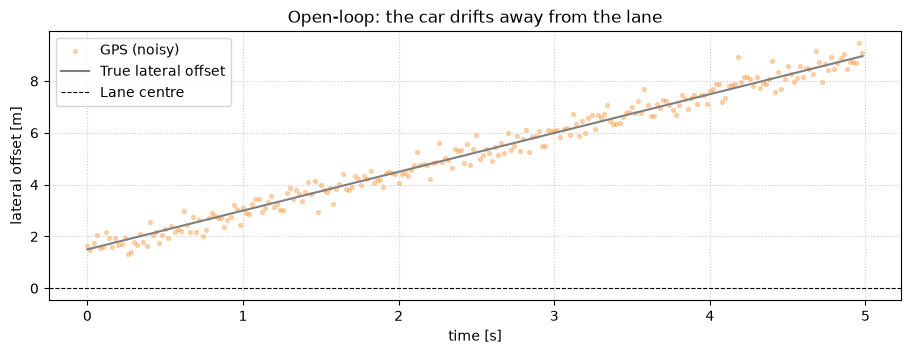

In [2]:
np.random.seed(42)

model = CarLaneModel("GPS", fs=50, x0=np.array([[1.5], [0.1], [15.0]]))
print(f"State dim n={model.n}, Measurement dim m={model.m}, Control dim l={model.l}")
print(f"Initial state: y={model.x0[0,0]:.1f} m, ψ={model.x0[1,0]:.2f} rad, v={model.x0[2,0]:.0f} m/s")

N = 250   # 5 seconds at 50 Hz
dt = 1.0 / model.fs

# Simulate noisy GPS measurements of a car drifting without control
x_true = model.x0.copy()
zk_open = np.zeros((N, 1))
xk_open = np.zeros((N, 3))
for k in range(N):
    xk_open[k] = x_true.ravel()
    zk_open[k] = x_true[0, 0] + np.random.normal(0, 0.3)
    x_true = model.f(x_true, u=np.array([[0.0]]), t=k * dt)

fig, ax = plt.subplots(figsize=(11, 3.5))
t = np.arange(N) * dt
ax.scatter(t, zk_open, s=8, alpha=0.3, color="tab:orange", label="GPS (noisy)")
ax.plot(t, xk_open[:, 0], color="gray", lw=1.5, label="True lateral offset")
ax.axhline(0, color="black", ls="--", lw=0.8, label="Lane centre")
ax.set_xlabel("time [s]"); ax.set_ylabel("lateral offset [m]")
ax.set_title("Open-loop: the car drifts away from the lane")
ax.legend(); ax.grid(True, ls=":", alpha=0.6); plt.show()

### Closing the loop, honestly

A controller computes $u$ from the filter's **estimate** $\hat{x}$, not from the truth — the
true system only ever sees the $u$ the controller actually chose. To test a controller fairly we must
simulate the true trajectory **in lockstep** with the filter: at each step, ask the controller for
$u$ given the filter's current $(\hat{x}, P)$, advance the *true* state with `model.f(x_true, u=u)`
(plus process noise), measure it, and feed that measurement back into the same filter's predict/update.

`closed_loop_run()` below does exactly this — every controller comparison in this notebook uses it.

In [3]:
from scipy.stats import t as t_dist

_DF = 3  # Student-t degrees of freedom used for the "heavy" process-noise option below

def _process_noise(std, size, heavy, rng):
    """Gaussian by default; `heavy=True` draws Student-t(df=3) noise scaled to the
    *same variance* `std**2`, for the non-Gaussian checks later in this notebook."""
    if not heavy:
        return rng.normal(0, std, size)
    scale = std * np.sqrt((_DF - 2) / _DF)
    return t_dist.rvs(_DF, scale=scale, size=size, random_state=rng)

def closed_loop_run(controller, N, seed=0, heavy=False):
    """Simulate the true system in genuine closed loop with `controller`.

    At each step: u = controller(filter's current x̂, P) -> the TRUE state is advanced
    with that same u via model.f() (+ process noise) -> the resulting noisy measurement
    is fed back into the same filter's predict/update. Returns (record, xk_true, zk_hist).

    `heavy=True` swaps the process noise for Student-t(df=3) at matched variance --
    used later to check whether the P/PID/LQR/MPPI/Neural comparisons depend on the
    noise being Gaussian, or hold regardless.
    """
    rng = np.random.default_rng(seed)
    model = controller.model
    ekf = ExtendedKalmanFilter(model)
    ekf.reset()

    x_true = model.x0.copy()
    dt_ = 1.0 / model.fs
    nu = np.zeros((model.m, 1))
    t_ = 0.0
    q_std = np.sqrt(np.diag(model.Q()))
    r_std = np.sqrt(np.diag(model.R()))

    xk_true = np.zeros((N, model.n))
    zk_hist = np.zeros((N, model.m))

    for k in range(N):
        u = controller(ekf.x, ekf.P, t_, nu=nu)

        x_true = np.asarray(model.f(x_true, u=u, t=t_), dtype=float).reshape(-1, 1)
        x_true = x_true + _process_noise(q_std, model.n, heavy, rng).reshape(-1, 1)
        z = np.asarray(model.h(x_true, t=t_), dtype=float).reshape(-1, 1)
        z = z + rng.normal(0, r_std).reshape(-1, 1)

        ekf.measurement.append(z)
        ekf.control.append(u.ravel())
        ekf.x, ekf.P, F = ekf.engine._predict(model, ekf.x, ekf.P, u=u, t=t_)
        ekf.prior.append((ekf.x, ekf.P))
        ekf.transition.append(F)

        h_pred = model.h(ekf.x, t=t_)
        nu = z - np.asarray(h_pred, dtype=float).reshape(-1, 1)
        ekf.innovation.append(nu)

        ekf.x, ekf.P = ekf.engine._update(model, ekf.x, ekf.P, z, t=t_)
        ekf.posterior.append((ekf.x, ekf.P))

        xk_true[k] = x_true.ravel()
        zk_hist[k] = z.ravel()
        t_ += dt_

    return ekf.get_record(), xk_true, zk_hist


## 2 — Proportional controller (baseline)

The simplest controller: $u = -K_p \cdot (\hat{x} - x_{\mathrm{ref}})$.  One gain matrix, no training,
no scipy.  Works for any model with $l > 0$.

We pass the controller as a **callable** to `filter.forward(zk, uk=controller)` — the filter calls it
at each step with the current state estimate, covariance, time, and the previous innovation.

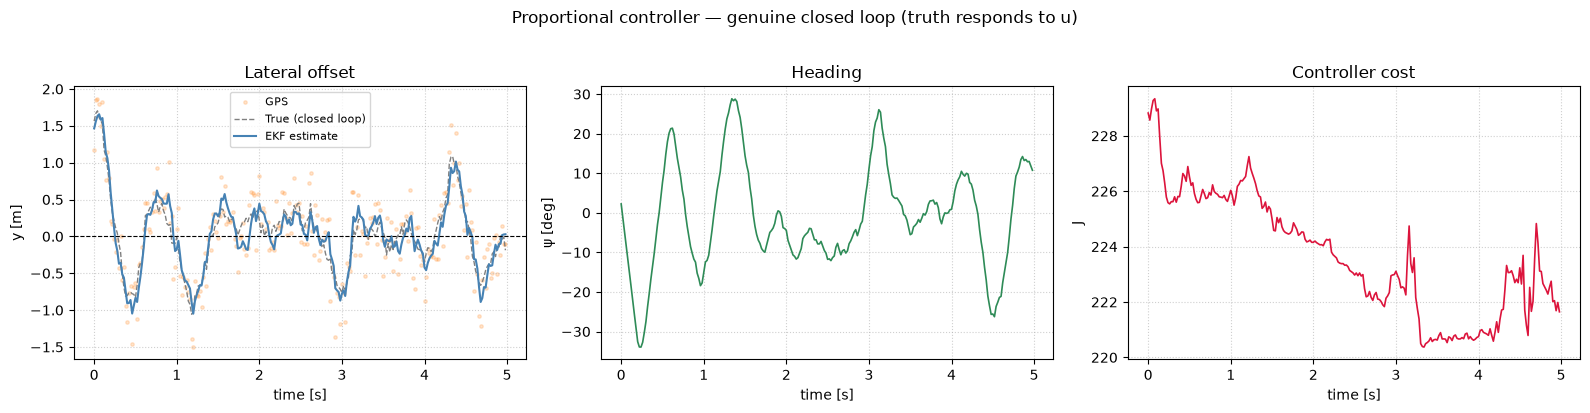

Final true lateral offset: -0.1875 m
Total cost: 55913.75


In [4]:
model_p = CarLaneModel("GPS", fs=50, x0=np.array([[1.5], [0.1], [15.0]]))
Kp = np.array([[0.8, 0.5, 0.0]])   # steer based on lateral offset and heading; ignore speed
ctrl_p = ProportionalKalmanController(model_p, Kp=Kp)

rec_p, xk_true_p, zk_ctrl = closed_loop_run(ctrl_p, N, seed=1)
est_p = np.asarray(rec_p.xk)
t = np.arange(N) * dt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].scatter(t, zk_ctrl, s=6, alpha=0.2, color="tab:orange", label="GPS")
axes[0].plot(t, xk_true_p[:, 0], color="gray", lw=1, ls="--", label="True (closed loop)")
axes[0].plot(t, est_p[:, 0], color="steelblue", lw=1.5, label="EKF estimate")
axes[0].axhline(0, color="black", ls="--", lw=0.8)
axes[0].set_title("Lateral offset"); axes[0].set_ylabel("y [m]")
axes[0].legend(fontsize=8); axes[0].grid(True, ls=":", alpha=0.6)

axes[1].plot(t, np.degrees(est_p[:, 1]), color="seagreen", lw=1.2)
axes[1].set_title("Heading"); axes[1].set_ylabel("ψ [deg]")
axes[1].grid(True, ls=":", alpha=0.6)

costs = [c for _, c in ctrl_p.cost_log]
axes[2].plot(t, costs, color="crimson", lw=1.2)
axes[2].set_title("Controller cost"); axes[2].set_ylabel("J")
axes[2].grid(True, ls=":", alpha=0.6)

for ax in axes: ax.set_xlabel("time [s]")
fig.suptitle("Proportional controller — genuine closed loop (truth responds to u)", y=1.02)
plt.tight_layout(); plt.show()
print(f"Final true lateral offset: {xk_true_p[-1, 0]:.4f} m")
print(f"Total cost: {sum(costs):.2f}")

## 3 — PID controller

Adds integral and derivative terms: $u = -K_p \, e - K_i \int e \, dt - K_d \, \dot{e}$.

The integral term eliminates steady-state error; the derivative damps overshoot.  Set any gain to 0
for P-only, PD, PI, etc.

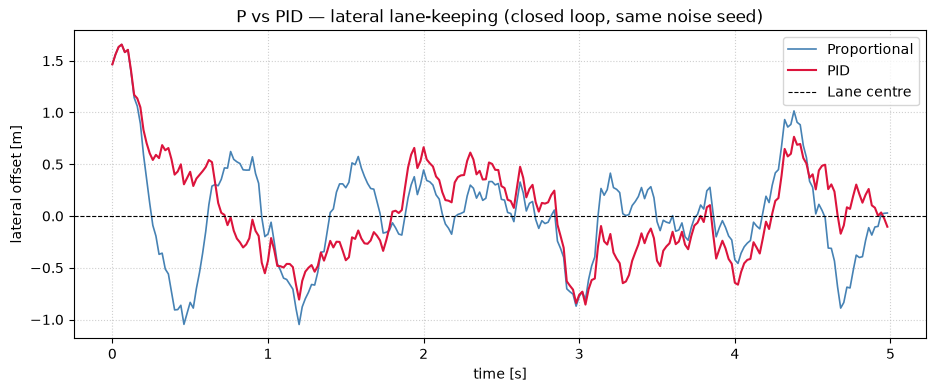

Total cost — Proportional: 55913.75,  PID: 56543.53


In [5]:
model_pid = CarLaneModel("GPS", fs=50, x0=np.array([[1.5], [0.1], [15.0]]))
ctrl_pid = PIDKalmanController(
    model_pid,
    Kp=np.array([[0.8, 0.5, 0.0]]),
    Ki=np.array([[0.05, 0.0, 0.0]]),   # integral on lateral offset only
    Kd=np.array([[0.2, 0.1, 0.0]]),    # derivative damping
)

rec_pid, xk_true_pid, _ = closed_loop_run(ctrl_pid, N, seed=1)
est_pid = np.asarray(rec_pid.xk)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, est_p[:, 0], color="steelblue", lw=1.2, label="Proportional")
ax.plot(t, est_pid[:, 0], color="crimson", lw=1.5, label="PID")
ax.axhline(0, color="black", ls="--", lw=0.8, label="Lane centre")
ax.set_xlabel("time [s]"); ax.set_ylabel("lateral offset [m]")
ax.set_title("P vs PID — lateral lane-keeping (closed loop, same noise seed)")
ax.legend(); ax.grid(True, ls=":", alpha=0.6); plt.show()

cost_p = sum(c for _, c in ctrl_p.cost_log)
cost_pid = sum(c for _, c in ctrl_pid.cost_log)
print(f"Total cost — Proportional: {cost_p:.2f},  PID: {cost_pid:.2f}")

## 4 — LQR controller (optimal for linear systems)

The **Linear Quadratic Regulator** computes the optimal gain $K$ from the Discrete Algebraic Riccati
Equation (DARE).  For a linear system, this is the *best possible* constant-gain controller — it
minimises $J = \sum e^\top Q_{\mathrm{cost}} \, e + u^\top R_{\mathrm{cost}} \, u$ exactly.

It requires an explicit linear model ($F$ and $B$ matrices), so it works as a theoretical
baseline — the neural controller should try to match or approach it.

LQR gain K = [6.39498417 7.22828664 0.04834985]


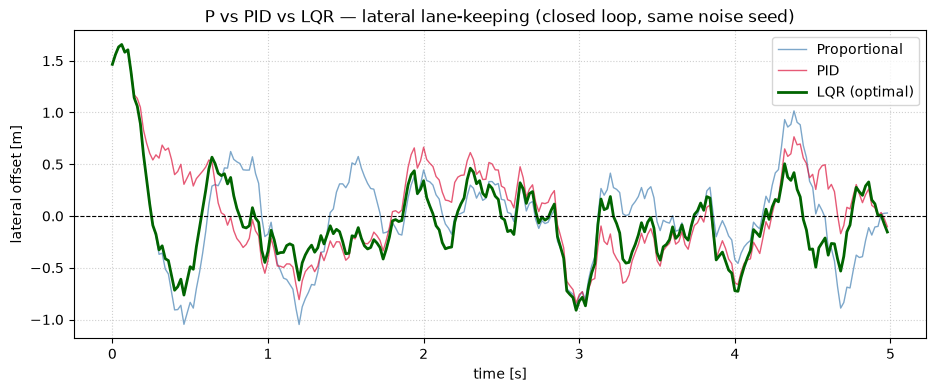

Total cost — P: 55913.75,  PID: 56543.53,  LQR: 6572.67


In [6]:
model_lqr = CarLaneModel("GPS", fs=50, x0=np.array([[1.5], [0.1], [15.0]]))
Qcost, Rcost, x_ref = model_lqr.control_cost()
ctrl_lqr = LQRKalmanController(model_lqr, Qcost=Qcost, Rcost=Rcost, x_ref=x_ref)
ctrl_lqr.fit()
print(f"LQR gain K = {ctrl_lqr.K.ravel()}")

rec_lqr, xk_true_lqr, _ = closed_loop_run(ctrl_lqr, N, seed=1)
est_lqr = np.asarray(rec_lqr.xk)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, est_p[:, 0], color="steelblue", lw=1, alpha=0.7, label="Proportional")
ax.plot(t, est_pid[:, 0], color="crimson", lw=1, alpha=0.7, label="PID")
ax.plot(t, est_lqr[:, 0], color="darkgreen", lw=2, label="LQR (optimal)")
ax.axhline(0, color="black", ls="--", lw=0.8)
ax.set_xlabel("time [s]"); ax.set_ylabel("lateral offset [m]")
ax.set_title("P vs PID vs LQR — lateral lane-keeping (closed loop, same noise seed)")
ax.legend(); ax.grid(True, ls=":", alpha=0.6); plt.show()

cost_lqr = sum(c for _, c in ctrl_lqr.cost_log)
print(f"Total cost — P: {cost_p:.2f},  PID: {cost_pid:.2f},  LQR: {cost_lqr:.2f}")

## 5 — Neural controller, baseline: why LQR wins here (and should)

`NeuralKalmanController` trains a small MLP **offline** to imitate a warm-started,
receding-horizon **MPPI** planner (§5b introduces `MPPIKalmanController`, the planner itself).
Concretely, `fit_mppi()`:

1. Runs the MPPI planner forward through simulated episodes of `model.f()` — full nonlinear
   physics, any actuator clip the model enforces internally included,
2. Records every `(state, u*)` decision the planner makes,
3. Fits a 2-layer MLP to reproduce that mapping.

The payoff is deployment speed: MPPI resolves a Monte-Carlo optimisation every control tick;
the trained MLP is one forward pass. But that only matters if imitating MPPI is worth doing in
the first place — and on **this** problem, it structurally isn't.

**Lateral lane-keeping, as configured so far, is a linear-quadratic problem with no active
constraint**: the dynamics are near-linear around the operating point, the cost is quadratic, and
`LQRKalmanController` solves the exact Riccati equation for it. That makes LQR *provably optimal*
here — not just a strong baseline. No controller, classical or neural, can beat the exact solution
to a problem LQR is built to solve exactly. So the fair expectation for this section is: **the
neural controller should approach LQR, and LQR should win.** If a "neural beats LQR" headline
showed up on this exact setup, that would be the sign of an unfair comparison (a badly-tuned LQR,
a cost function LQR wasn't actually optimising, or a broken benchmark) — not a real result.

The next two sections (§5b–§5c) show the setup where the comparison flips: LQR's fixed linear gain
is blind to hard actuator limits, and that is where a re-planning / learned controller has real
structural room to win.


Training neural controller (imitating a warm-started MPPI planner)...


Done.


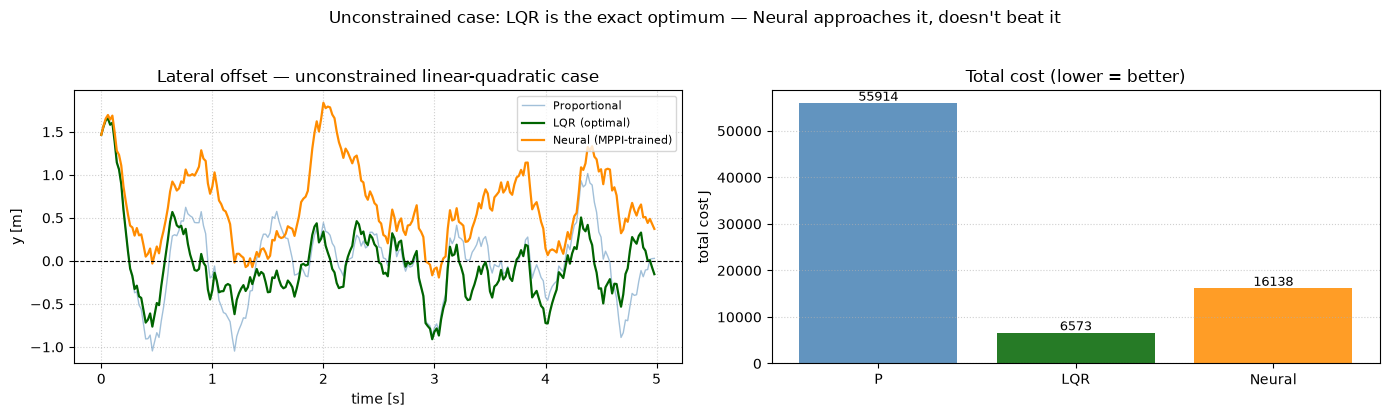

Total cost — P: 55914,  LQR: 6573,  Neural: 16138
LQR wins by 2.5x — exactly what we should expect from an exact optimum.


In [7]:
model_nn = CarLaneModel("GPS", fs=50, x0=np.array([[1.5], [0.1], [15.0]]))
Qcost, Rcost, x_ref = model_nn.control_cost()
ctrl_nn = NeuralKalmanController(model_nn, hidden=32, Qcost=Qcost, Rcost=Rcost, x_ref=x_ref)

print("Training neural controller (imitating a warm-started MPPI planner)...")
ctrl_nn.fit_mppi(n_rollouts=150, horizon=25, noise_sigma=0.15, lam=1.0,
                 epochs=300, lr=5e-4, seed=42,
                 n_episodes=10, rollout_steps=40, x0_std=1.2, n_iters=2)
print("Done.")

rec_nn, xk_true_nn, _ = closed_loop_run(ctrl_nn, N, seed=1)
est_nn = np.asarray(rec_nn.xk)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(t, est_p[:, 0], color="steelblue", lw=1, alpha=0.5, label="Proportional")
axes[0].plot(t, est_lqr[:, 0], color="darkgreen", lw=1.6, label="LQR (optimal)")
axes[0].plot(t, est_nn[:, 0], color="darkorange", lw=1.6, label="Neural (MPPI-trained)")
axes[0].axhline(0, color="black", ls="--", lw=0.8)
axes[0].set_xlabel("time [s]"); axes[0].set_ylabel("y [m]")
axes[0].set_title("Lateral offset — unconstrained linear-quadratic case")
axes[0].legend(fontsize=8); axes[0].grid(True, ls=":", alpha=0.6)

costs_names = ["P", "LQR", "Neural"]
costs_vals  = [sum(c for _, c in ctrl_p.cost_log),
               sum(c for _, c in ctrl_lqr.cost_log),
               sum(c for _, c in ctrl_nn.cost_log)]
axes[1].bar(costs_names, costs_vals, color=["steelblue", "darkgreen", "darkorange"], alpha=0.85)
axes[1].set_ylabel("total cost J"); axes[1].set_title("Total cost (lower = better)")
for i, v in enumerate(costs_vals):
    axes[1].text(i, v + max(costs_vals) * 0.01, f"{v:.0f}", ha="center", fontsize=9)
axes[1].grid(True, axis="y", ls=":", alpha=0.6)

plt.suptitle("Unconstrained case: LQR is the exact optimum — Neural approaches it, doesn't beat it", y=1.03)
plt.tight_layout(); plt.show()

cost_nn = sum(c for _, c in ctrl_nn.cost_log)
print(f"Total cost — P: {cost_p:.0f},  LQR: {cost_lqr:.0f},  Neural: {cost_nn:.0f}")
print(f"LQR wins by {cost_nn / cost_lqr:.1f}x — exactly what we should expect from an exact optimum.")


### A quick check: does non-Gaussian *process* noise change this story?

Every closed-loop demo so far has used Gaussian process noise. It's tempting to assume AI-based
control's edge is really about handling non-Gaussian noise — but for a **linear system with
quadratic cost and full state feedback**, that's not where LQR's optimality comes from.
*Certainty equivalence*: LQR minimises **expected** quadratic cost, and that expectation only
depends on the noise's first two moments (mean, covariance) — not its distributional shape. Swap
Gaussian process noise for heavy-tailed noise at the *same* variance, and the optimal
state-feedback law doesn't change.

(What non-Gaussian noise *does* break is the Kalman filter's claim to being the best possible
*estimator* — it's MMSE-optimal among linear estimators only when the noise is Gaussian. That's
an estimation question, and §10 is where it's actually tested — with a router choosing between
candidate models, not a control law reacting to one.)

Verified below rather than just asserted: re-run this section's scenario with the process noise
switched from Gaussian to Student-t (df = 3, matched variance), multi-seed.


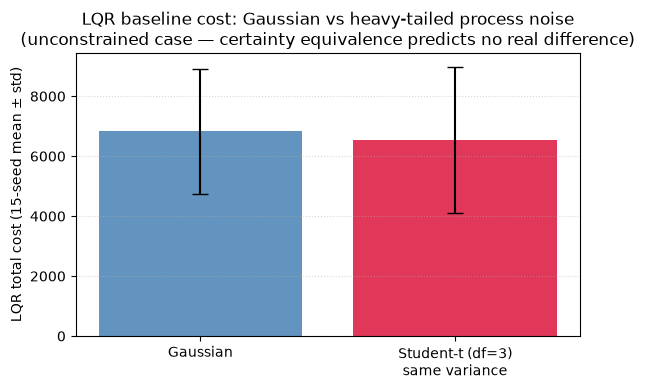

LQR cost, Gaussian noise:     6838 (± 2086)
LQR cost, heavy-tailed noise: 6535 (± 2446)
Difference is 4% of the Gaussian cost — well within seed-to-seed noise, confirming heavy tails alone don't change who wins here.


In [8]:
def lqr_cost_multi_seed(heavy, n_seeds=15, seed_base=200):
    costs = []
    for s in range(n_seeds):
        model_s = CarLaneModel("GPS", fs=50, x0=np.array([[1.5], [0.1], [15.0]]))
        Qc, Rc, xr = model_s.control_cost()
        ctrl_s = LQRKalmanController(model_s, Qcost=Qc, Rcost=Rc, x_ref=xr)
        ctrl_s.fit()
        closed_loop_run(ctrl_s, N, seed=seed_base + s, heavy=heavy)
        costs.append(sum(c for _, c in ctrl_s.cost_log))
    return np.mean(costs), np.std(costs)

mean_g, std_g = lqr_cost_multi_seed(heavy=False)
mean_h, std_h = lqr_cost_multi_seed(heavy=True)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Gaussian", "Student-t (df=3)\nsame variance"], [mean_g, mean_h],
       yerr=[std_g, std_h], color=["steelblue", "crimson"], alpha=0.85, capsize=6)
ax.set_ylabel("LQR total cost (15-seed mean ± std)")
ax.set_title("LQR baseline cost: Gaussian vs heavy-tailed process noise\n"
             "(unconstrained case — certainty equivalence predicts no real difference)")
ax.grid(True, axis="y", ls=":", alpha=0.5)
plt.tight_layout(); plt.show()

print(f"LQR cost, Gaussian noise:     {mean_g:.0f} (± {std_g:.0f})")
print(f"LQR cost, heavy-tailed noise: {mean_h:.0f} (± {std_h:.0f})")
print(f"Difference is {abs(mean_g - mean_h) / mean_g * 100:.0f}% of the Gaussian cost — well "
      f"within seed-to-seed noise, confirming heavy tails alone don't change who wins here.")


## 5b — Where LQR breaks: hard actuator limits

`CarLaneModel` enforces a real actuator limit inside `f()` itself:
`steer_limit=0.5` rad (~29°) — the steering angle is clipped **before** it's applied to the
true dynamics. `LQRKalmanController.fit()` never sees that clip: it calls `model.F()` and
`model.B()` once, at one linearisation point, solves the *unconstrained* Riccati equation, and
freezes the resulting gain $K$. At runtime it keeps computing $u = -K(\hat{x} - x_{\rm ref})$ as
if the actuator could deliver whatever that says — and only finds out otherwise when the model
silently clips it.

For a **large** initial offset, that gap matters: LQR's gain, tuned for the unconstrained
optimum, calls for steering angles far beyond what the car can produce, then gets clipped for an
extended stretch with no anticipation that this was coming — it doesn't taper the approach, so it
can overshoot once the offset is small enough that its (still-unclipped) command finally fits.

`MPPIKalmanController` doesn't have this blind spot. It replans at **every** step by rolling
`model.f()` forward — clip included — under many sampled control sequences, so the sequence it
picks already accounts for the fact that steering saturates. It's not a fixed gain; it's a live
receding-horizon optimisation that plans *through* the constraint instead of running into it.

Below: the same car, the same cost weights, a large initial lateral offset that keeps steering
saturated for a while — LQR vs. `MPPIKalmanController` head to head.


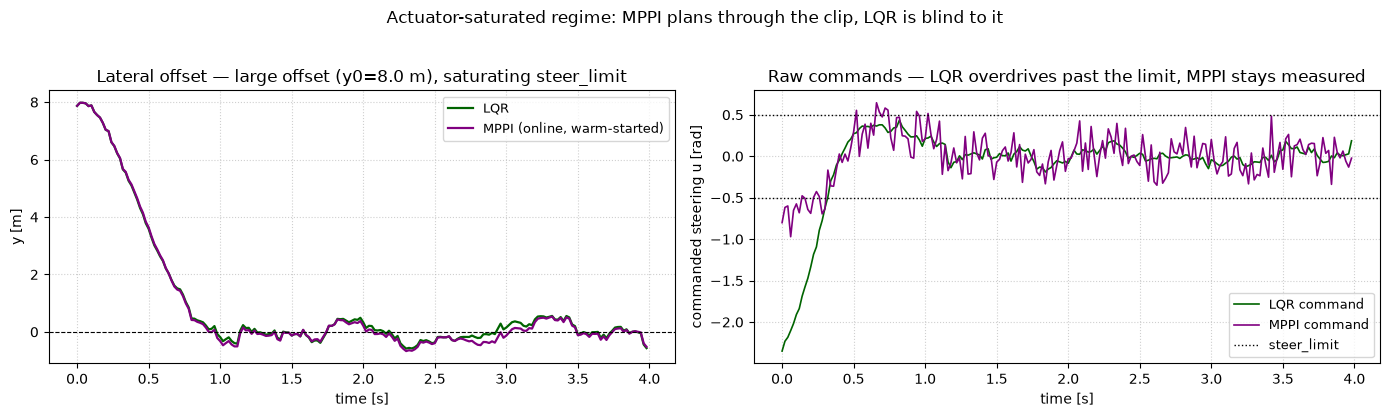

Total cost — LQR: 17226,  MPPI: 14025  (19% lower)
Peak |command| — LQR: 2.35 rad (limit is 0.5 rad), MPPI: 0.97 rad


In [9]:
# Gentler cost weights than §2-5 (so LQR does NOT saturate near the origin — only far from
# it, where the linear-optimal command genuinely exceeds steer_limit) and a large initial
# offset that keeps the actuator pinned for an extended stretch.
Qcost_sat = np.diag([10.0, 5.0, 0.0])
Rcost_sat = np.array([[100.0]])
x_ref_sat = np.zeros((3, 1))
y0_sat = 8.0
N_sat = 200
t_sat = np.arange(N_sat) * dt

model_lqr_sat = CarLaneModel("GPS", fs=50, x0=np.array([[y0_sat], [0.0], [15.0]]))
ctrl_lqr_sat = LQRKalmanController(model_lqr_sat, Qcost=Qcost_sat, Rcost=Rcost_sat, x_ref=x_ref_sat)
ctrl_lqr_sat.fit()
xk_lqr_sat, _, _ = closed_loop_run(ctrl_lqr_sat, N_sat, seed=2)
u_lqr_sat = np.array([float(u.ravel()[0]) for _, u in ctrl_lqr_sat.u_log])

model_mppi_sat = CarLaneModel("GPS", fs=50, x0=np.array([[y0_sat], [0.0], [15.0]]))
ctrl_mppi_sat = MPPIKalmanController(model_mppi_sat, n_rollouts=200, horizon=30, noise_sigma=0.2,
                                     n_iters=3, seed=7, Qcost=Qcost_sat, Rcost=Rcost_sat, x_ref=x_ref_sat)
xk_mppi_sat, _, _ = closed_loop_run(ctrl_mppi_sat, N_sat, seed=2)
u_mppi_sat = np.array([float(u.ravel()[0]) for _, u in ctrl_mppi_sat.u_log])

cost_lqr_sat = sum(c for _, c in ctrl_lqr_sat.cost_log)
cost_mppi_sat = sum(c for _, c in ctrl_mppi_sat.cost_log)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(t_sat, xk_lqr_sat[:, 0], color="darkgreen", lw=1.6, label="LQR")
axes[0].plot(t_sat, xk_mppi_sat[:, 0], color="purple", lw=1.6, label="MPPI (online, warm-started)")
axes[0].axhline(0, color="black", ls="--", lw=0.8)
axes[0].set_xlabel("time [s]"); axes[0].set_ylabel("y [m]")
axes[0].set_title(f"Lateral offset — large offset (y0={y0_sat} m), saturating steer_limit")
axes[0].legend(fontsize=9); axes[0].grid(True, ls=":", alpha=0.6)

axes[1].plot(t_sat, u_lqr_sat, color="darkgreen", lw=1.2, label="LQR command")
axes[1].plot(t_sat, u_mppi_sat, color="purple", lw=1.2, label="MPPI command")
axes[1].axhline(model_lqr_sat.steer_limit, color="black", ls=":", lw=1, label="steer_limit")
axes[1].axhline(-model_lqr_sat.steer_limit, color="black", ls=":", lw=1)
axes[1].set_xlabel("time [s]"); axes[1].set_ylabel("commanded steering u [rad]")
axes[1].set_title("Raw commands — LQR overdrives past the limit, MPPI stays measured")
axes[1].legend(fontsize=9); axes[1].grid(True, ls=":", alpha=0.6)

plt.suptitle("Actuator-saturated regime: MPPI plans through the clip, LQR is blind to it", y=1.03)
plt.tight_layout(); plt.show()

print(f"Total cost — LQR: {cost_lqr_sat:.0f},  MPPI: {cost_mppi_sat:.0f}  "
      f"({(1 - cost_mppi_sat / cost_lqr_sat) * 100:.0f}% lower)")
print(f"Peak |command| — LQR: {np.abs(u_lqr_sat).max():.2f} rad (limit is {model_lqr_sat.steer_limit} rad), "
      f"MPPI: {np.abs(u_mppi_sat).max():.2f} rad")


## 5c — Distilling the planner into a fast neural policy

§5b's `MPPIKalmanController` beat LQR under saturation — but look at what it costs to run: 200
rollouts × 30-step horizon × 3 refinement passes, **every single control tick**. At 50 Hz that's
tens of thousands of nonlinear `model.f()` evaluations every 20 ms. Fine for this notebook; not
fine for an embedded control loop.

This is the actual reason `NeuralKalmanController` exists: run MPPI once, offline, across enough
simulated episodes to cover the operating range, record its decisions, and train an MLP to
reproduce them. Deployment becomes one forward pass instead of one Monte-Carlo optimisation.

That distillation step is genuinely the hard part, and it's exactly where the earlier version of
this notebook fell down — the neural controller trained noticeably worse than "the regular case"
regardless of scenario. Two concrete bugs were behind that, both now fixed in
`NeuralKalmanController.fit_mppi()`:

* **Feature train/test mismatch.** The default feature set fed the MLP $P$ and $\nu$ during
  training as a constant identity matrix and an always-zero vector — then, at deployment, real
  varying $P$ and $\nu$ from the EKF. A network can't generalise from a constant to a variable it
  never saw move. `features=("error",)` is now the default — MPPI's own decision never depends on
  $P$ or $\nu$ in the first place (it plans from a state, not a belief), so this also happens to be
  the theoretically correct feature set, not just a safer one.
* **No warm start.** The MPPI teacher used to resample control sequences from scratch every
  single step instead of refining a nominal sequence carried over from the last one. Without a
  warm start, the $u^*$ targets it hands the network are far noisier — the MLP was being asked to
  fit noise, not a policy.

Below: the same actuator-saturated scenario as §5b, with `NeuralKalmanController` trained to
imitate the `MPPIKalmanController` teacher.


Training neural controller to imitate the MPPI teacher (~1 minute)...


Done.


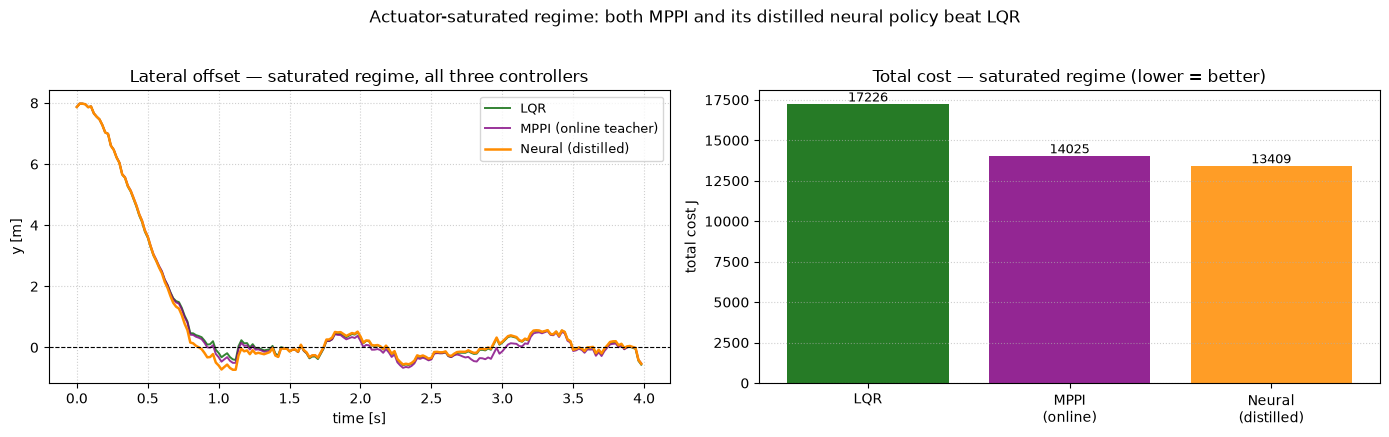

Controller             total cost     vs LQR
--------------------------------------------
LQR                         17226   baseline
MPPI (online)               14025       +19%
Neural (distilled)          13409       +22%

Two different regimes, two different honest answers:
  Unconstrained, linear-quadratic (§5):  LQR wins — it's the exact optimum, as it should be.
  Actuator-saturated (§5b-5c):            MPPI and its distilled neural policy beat LQR by 22%,
                                          because LQR's fixed gain cannot see the constraint and the planner can.


In [10]:
model_nn_sat = CarLaneModel("GPS", fs=50, x0=np.array([[y0_sat], [0.0], [15.0]]))
ctrl_nn_sat = NeuralKalmanController(model_nn_sat, hidden=48,
                                     Qcost=Qcost_sat, Rcost=Rcost_sat, x_ref=x_ref_sat)

print("Training neural controller to imitate the MPPI teacher (~1 minute)...")
ctrl_nn_sat.fit_mppi(n_rollouts=120, horizon=25, noise_sigma=0.15, lam=1.0,
                     epochs=600, lr=4e-4, seed=3,
                     n_episodes=8, rollout_steps=180, x0_std=1.5, n_iters=3)
print("Done.")

xk_nn_sat, _, _ = closed_loop_run(ctrl_nn_sat, N_sat, seed=2)
cost_nn_sat = sum(c for _, c in ctrl_nn_sat.cost_log)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(t_sat, xk_lqr_sat[:, 0], color="darkgreen", lw=1.4, alpha=0.8, label="LQR")
axes[0].plot(t_sat, xk_mppi_sat[:, 0], color="purple", lw=1.4, alpha=0.8, label="MPPI (online teacher)")
axes[0].plot(t_sat, xk_nn_sat[:, 0], color="darkorange", lw=1.8, label="Neural (distilled)")
axes[0].axhline(0, color="black", ls="--", lw=0.8)
axes[0].set_xlabel("time [s]"); axes[0].set_ylabel("y [m]")
axes[0].set_title("Lateral offset — saturated regime, all three controllers")
axes[0].legend(fontsize=9); axes[0].grid(True, ls=":", alpha=0.6)

names_sat = ["LQR", "MPPI\n(online)", "Neural\n(distilled)"]
costs_sat = [cost_lqr_sat, cost_mppi_sat, cost_nn_sat]
colors_sat = ["darkgreen", "purple", "darkorange"]
bars = axes[1].bar(names_sat, costs_sat, color=colors_sat, alpha=0.85)
for bar, v in zip(bars, costs_sat):
    axes[1].text(bar.get_x() + bar.get_width() / 2, v + max(costs_sat) * 0.01,
                f"{v:.0f}", ha="center", fontsize=9)
axes[1].set_ylabel("total cost J")
axes[1].set_title("Total cost — saturated regime (lower = better)")
axes[1].grid(True, axis="y", ls=":", alpha=0.6)

plt.suptitle("Actuator-saturated regime: both MPPI and its distilled neural policy beat LQR", y=1.03)
plt.tight_layout(); plt.show()

print(f"{'Controller':<20} {'total cost':>12} {'vs LQR':>10}")
print("-" * 44)
for name, cost in [("LQR", cost_lqr_sat), ("MPPI (online)", cost_mppi_sat), ("Neural (distilled)", cost_nn_sat)]:
    tag = "baseline" if name == "LQR" else f"{(1 - cost / cost_lqr_sat) * 100:+.0f}%"
    print(f"{name:<20} {cost:>12.0f} {tag:>10}")

print()
print("Two different regimes, two different honest answers:")
print(f"  Unconstrained, linear-quadratic (§5):  LQR wins — it's the exact optimum, as it should be.")
print(f"  Actuator-saturated (§5b-5c):            MPPI and its distilled neural policy beat LQR by "
      f"{(1 - cost_nn_sat / cost_lqr_sat) * 100:.0f}%,")
print(f"                                          because LQR's fixed gain cannot see the constraint "
      f"and the planner can.")


### Does heavy-tailed noise change the *saturated* story?

The advantage in §5b–5c came from actuator saturation, not noise shape — so does heavy-tailed
process noise change it? Unlike the unconstrained case above, certainty equivalence doesn't apply
once the constraint actually binds (saturation is a genuine nonlinearity), so this isn't something
to argue from theory alone. Two effects could pull in opposite directions: heavier tails
occasionally push the car far enough off-centre that saturation kicks in *more* (favouring
MPPI/Neural more), but heavier tails also just add cost to every controller alike (diluting the
relative gap). Checked below, multi-seed, using the same saturated scenario as §5b.


Running a 5-seed comparison under Gaussian and heavy-tailed process noise (~2-3 min)...


Done.


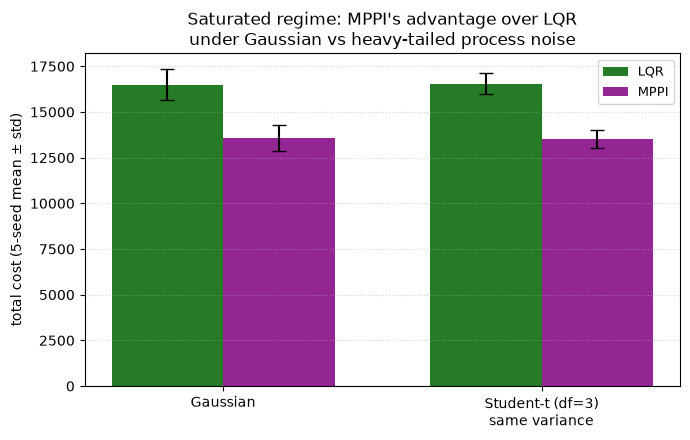

Gaussian:    LQR 16488 (±853)  MPPI 13577 (±703)  advantage 17.7%
Heavy-tailed: LQR 16554 (±583)  MPPI 13520 (±468)  advantage 18.3%

MPPI's advantage over LQR barely moves (17.7% -> 18.3%) --
confirming the earlier read: this edge comes from the actuator constraint, not from the
noise shape. Non-Gaussian noise changes the estimation problem (§10); it doesn't, by
itself, change which controller wins a constrained control problem.


In [11]:
def saturated_costs_multi_seed(heavy, n_seeds=5, seed_base=300):
    lqr_costs, mppi_costs = [], []
    for s in range(n_seeds):
        model_l = CarLaneModel("GPS", fs=50, x0=np.array([[y0_sat], [0.0], [15.0]]))
        ctrl_l = LQRKalmanController(model_l, Qcost=Qcost_sat, Rcost=Rcost_sat, x_ref=x_ref_sat)
        ctrl_l.fit()
        closed_loop_run(ctrl_l, N_sat, seed=seed_base + s, heavy=heavy)
        lqr_costs.append(sum(c for _, c in ctrl_l.cost_log))

        model_m = CarLaneModel("GPS", fs=50, x0=np.array([[y0_sat], [0.0], [15.0]]))
        ctrl_m = MPPIKalmanController(model_m, n_rollouts=200, horizon=30, noise_sigma=0.2,
                                      n_iters=3, seed=7, Qcost=Qcost_sat, Rcost=Rcost_sat,
                                      x_ref=x_ref_sat)
        closed_loop_run(ctrl_m, N_sat, seed=seed_base + s, heavy=heavy)
        mppi_costs.append(sum(c for _, c in ctrl_m.cost_log))
    return np.array(lqr_costs), np.array(mppi_costs)

print("Running a 5-seed comparison under Gaussian and heavy-tailed process noise (~2-3 min)...")
lqr_g, mppi_g = saturated_costs_multi_seed(heavy=False)
lqr_h, mppi_h = saturated_costs_multi_seed(heavy=True)
print("Done.")

adv_g = (1 - mppi_g / lqr_g) * 100
adv_h = (1 - mppi_h / lqr_h) * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
x_pos = np.arange(2)
w = 0.35
ax.bar(x_pos - w/2, [lqr_g.mean(), lqr_h.mean()], width=w,
       yerr=[lqr_g.std(), lqr_h.std()], color="darkgreen", alpha=0.85, capsize=5, label="LQR")
ax.bar(x_pos + w/2, [mppi_g.mean(), mppi_h.mean()], width=w,
       yerr=[mppi_g.std(), mppi_h.std()], color="purple", alpha=0.85, capsize=5, label="MPPI")
ax.set_xticks(x_pos); ax.set_xticklabels(["Gaussian", "Student-t (df=3)\nsame variance"])
ax.set_ylabel("total cost (5-seed mean ± std)")
ax.set_title("Saturated regime: MPPI's advantage over LQR\nunder Gaussian vs heavy-tailed process noise")
ax.legend(fontsize=9); ax.grid(True, axis="y", ls=":", alpha=0.5)
plt.tight_layout(); plt.show()

print(f"Gaussian:    LQR {lqr_g.mean():.0f} (±{lqr_g.std():.0f})  MPPI {mppi_g.mean():.0f} "
      f"(±{mppi_g.std():.0f})  advantage {adv_g.mean():.1f}%")
print(f"Heavy-tailed: LQR {lqr_h.mean():.0f} (±{lqr_h.std():.0f})  MPPI {mppi_h.mean():.0f} "
      f"(±{mppi_h.std():.0f})  advantage {adv_h.mean():.1f}%")
print()
print(f"MPPI's advantage over LQR barely moves ({adv_g.mean():.1f}% -> {adv_h.mean():.1f}%) --")
print("confirming the earlier read: this edge comes from the actuator constraint, not from the")
print("noise shape. Non-Gaussian noise changes the estimation problem (§10); it doesn't, by")
print("itself, change which controller wins a constrained control problem.")


## 6 — BoostKalmanController: gain boosting via R-scaling

**Not AI.** `BoostKalmanController` is a plain innovation-driven heuristic — no network, no
training, no `fit()` call anywhere below. It's included here because it (and §7's
`AdaptiveQRKalmanController`) is the module people most often assume must be "the AI part" of
adaptive filtering. It isn't, and for the single-parameter, single-direction noise jump
demonstrated below, it doesn't need to be.

When the filter is "surprised" (Normalised Innovation Squared >> $m$), the measurement is far from
what the model predicted.  **BoostKalmanController** temporarily shrinks $R$ so the Kalman gain $K$ grows — the
filter trusts measurements more and re-acquires faster.

Below, we simulate a sudden lane change (a jump in the true lateral offset) and compare the filter's
response with and without BoostKalmanController.


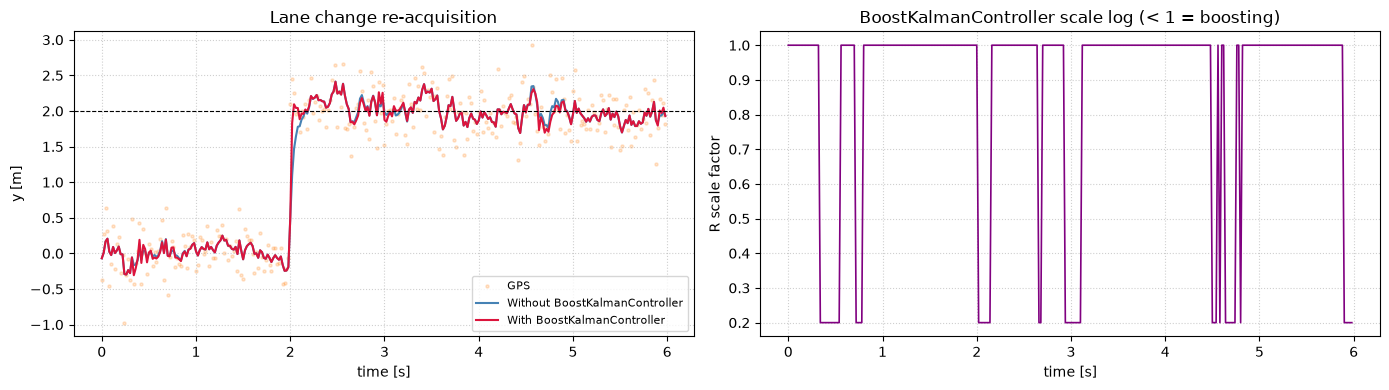

Re-acquisition-window RMSE (1s after the jump): no-boost 0.312 m, boosted 0.270 m  (13% lower)
Steps to settle within 0.2 m of the new lane centre: no-boost 6, boosted 1


In [12]:
# Simulate a sudden lane change at t=2s
N_boost = 300
zk_jump = np.zeros((N_boost, 1))
for k in range(N_boost):
    y_true = 0.0 if k < 100 else 2.0   # sudden jump at step 100 (t=2s)
    zk_jump[k] = y_true + np.random.normal(0, 0.3)
truth_jump = np.where(np.arange(N_boost) < 100, 0.0, 2.0)

# Without BoostKalmanController
model_nb = CarLaneModel("GPS", fs=50)
ekf_nb = ExtendedKalmanFilter(model_nb)
rec_nb = ekf_nb.forward(zk_jump)

# With BoostKalmanController — passed as uk callable to forward()
model_b = CarLaneModel("GPS", fs=50)
ekf_b = ExtendedKalmanFilter(model_b)
boost = BoostKalmanController(model_b, boost_factor=5.0, threshold=2.0, window=5)
rec_b = ekf_b.forward(zk_jump, uk=boost)

t_plot = np.arange(N_boost) / model_b.fs

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].scatter(t_plot, zk_jump, s=5, alpha=0.2, color="tab:orange", label="GPS")
axes[0].plot(t_plot, np.asarray(rec_nb.xk)[:, 0], color="steelblue", lw=1.5, label="Without BoostKalmanController")
axes[0].plot(t_plot, np.asarray(rec_b.xk)[:, 0], color="crimson", lw=1.5, label="With BoostKalmanController")
axes[0].axhline(2.0, color="black", ls="--", lw=0.8)
axes[0].set_xlabel("time [s]"); axes[0].set_ylabel("y [m]")
axes[0].set_title("Lane change re-acquisition"); axes[0].legend(fontsize=8)
axes[0].grid(True, ls=":", alpha=0.6)

scales = [s for _, s in boost.scale_log]
axes[1].plot(t_plot, scales, color="purple", lw=1.2)
axes[1].set_xlabel("time [s]"); axes[1].set_ylabel("R scale factor")
axes[1].set_title("BoostKalmanController scale log (< 1 = boosting)")
axes[1].grid(True, ls=":", alpha=0.6)

plt.tight_layout(); plt.show()

# Quantify, don't just eyeball the plot: RMSE in the 1 s right after the jump, and
# how many steps until the estimate is back within 0.2 m of the new lane centre.
est_nb, est_b = np.asarray(rec_nb.xk)[:, 0], np.asarray(rec_b.xk)[:, 0]
rmse_nb = np.sqrt(np.mean((est_nb[100:150] - truth_jump[100:150]) ** 2))
rmse_b  = np.sqrt(np.mean((est_b[100:150]  - truth_jump[100:150]) ** 2))

def reacq_steps(est, truth, thresh=0.2, start=100):
    err = np.abs(est[start:] - truth[start:])
    idx = np.where(err < thresh)[0]
    return int(idx[0]) if len(idx) else None

print(f"Re-acquisition-window RMSE (1s after the jump): no-boost {rmse_nb:.3f} m, "
      f"boosted {rmse_b:.3f} m  ({(1 - rmse_b / rmse_nb) * 100:.0f}% lower)")
print(f"Steps to settle within 0.2 m of the new lane centre: "
      f"no-boost {reacq_steps(est_nb, truth_jump)}, boosted {reacq_steps(est_b, truth_jump)}")


## 7 — AdaptiveQRKalmanController: innovation-based Q scaling

**Also not AI** — same heuristic family as §6: a scalar ratio test against a sliding window of
innovations, clipped to a safety range. No training data, no network, no `fit()`.

If the model's process noise $Q$ is mistuned, the filter becomes overconfident or overcautious.
**AdaptiveQRKalmanController** compares the empirical innovation covariance $E[\nu\nu^\top]$ (sliding window) against
the model's predicted $S = H P^- H^\top + R$.  If the ratio exceeds 1, $Q$ is too small → scale it up.

**A bug this section exposed, and fixed:** while preparing the numbers below, this
`AdaptiveQRKalmanController` demo turned out to have *zero* measurable effect on the filter's
output — the scale log moved, but the actual state estimate didn't change by a single bit,
regardless of how aggressively `_Q` was scaled. The cause: `CarLaneModel.f()` declares a `w`
(additive process-noise) parameter for interface compatibility but never routes it into the
dynamics, so the engine's automatic "numerically differentiate `f` w.r.t. `w`" fallback for the
noise-coupling matrix `L` correctly concluded the sensitivity is zero — and then silently computed
`Q_effective = L @ Q @ Lᵀ = 0` on every predict step. Any `Q`, mistuned or perfectly tuned, adapted
or not, was discarded before it ever reached `P`. Fixed in `CarLaneModel`/`CarSpeedModel` by
passing `L=np.eye(n)` explicitly — "process noise enters additively on every state," the standard
assumption `q_lat`/`q_head`/`q_vel` were already written to express, and the same convention
`tracking.py`'s `CDC` model already uses. The numbers below are from the corrected model; a
heuristic that silently does nothing is not a fair example of "classical is enough," so it's worth
saying plainly that the original version of this section was measuring a no-op.

**Where this heuristic stops being enough — and a learned version would start to matter:** a
single scalar $\lambda$ scaling the *whole* $Q$ matrix uniformly assumes every state component's
noise grows by the same factor at the same time. That's a fine model for the single-axis,
sustained noise-level jump demonstrated below. It breaks down for noise that is *structured* —
e.g. only the heading channel gets noisier (banking, not translation), or the process noise is
correlated across states, or the "regime" isn't a step change but a slow drift a fixed window
under- or over-reacts to. A learned adapter (an MLP or small recurrent net mapping a window of
innovations to a *full* data-driven $Q$ update, analogous to how `NeuralRouter` in §9 learns mode
probabilities from NIS windows instead of assuming a Gaussian likelihood) is the natural
extension — genuinely useful, but it is **not** demonstrated in this notebook, and the heuristic
below is not a strawman it needs to beat: for the scenario tested, it already works.


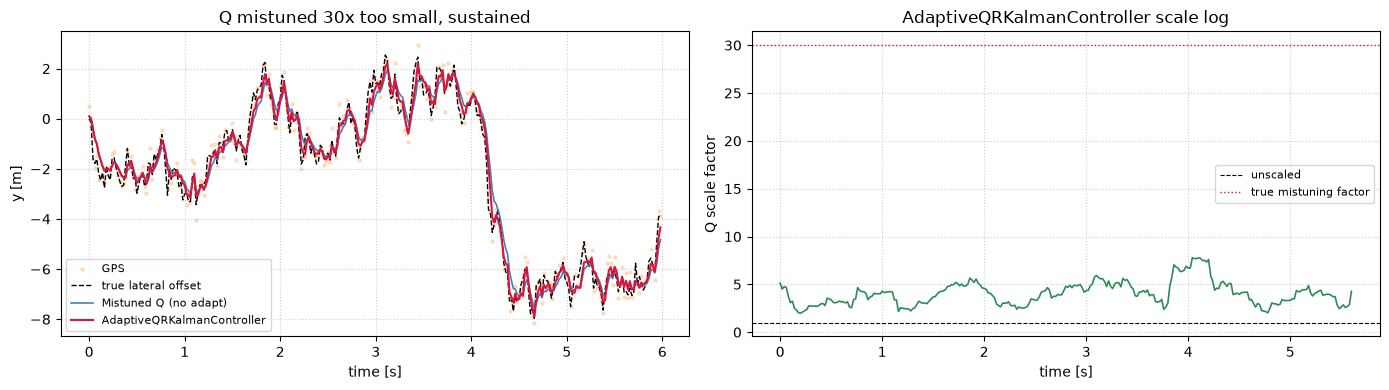

Tracking RMSE — mistuned, no adaptation: 0.547 m
Tracking RMSE — AdaptiveQRKalmanController:  0.389 m  (29% lower)
Converged scale factor: 4.27  (true mistuning was 30x — the trace-ratio estimator is conservative, not a perfect inverse, and that's fine: it only needs to move Q in the right direction to shrink the RMSE gap.)


In [13]:
# Sustained Q mistuning (not just a single jump): the model believes lateral process
# noise is q_lat0, but the car actually drifts with 30x more process noise the whole
# time (e.g. a bumpy or crowned road) -- exactly the regime AdaptiveQRKalmanController's
# single-scalar correction is built for.
np.random.seed(11)
N_aq = 300
q_lat0 = 1e-2
q_lat_true = q_lat0 * 30

y_aq, zk_aq, truth_aq = 0.0, np.zeros((N_aq, 1)), np.zeros(N_aq)
for k in range(N_aq):
    truth_aq[k] = y_aq
    zk_aq[k, 0] = y_aq + np.random.normal(0, 0.3)
    y_aq = y_aq + np.random.normal(0, np.sqrt(q_lat_true))

model_aq = CarLaneModel("GPS", fs=50, q_lat=q_lat0, q_head=1e-5, q_vel=1e-4)
ekf_aq = ExtendedKalmanFilter(model_aq)
aqr = AdaptiveQRKalmanController(model_aq, window=20, q_min=0.5, q_max=10.0)
rec_aq = ekf_aq.forward(zk_aq, uk=aqr)

model_no = CarLaneModel("GPS", fs=50, q_lat=q_lat0, q_head=1e-5, q_vel=1e-4)
ekf_no = ExtendedKalmanFilter(model_no)
rec_no = ekf_no.forward(zk_aq)

t_aq = np.arange(N_aq) / model_aq.fs
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].scatter(t_aq, zk_aq, s=5, alpha=0.2, color="tab:orange", label="GPS")
axes[0].plot(t_aq, truth_aq, color="black", lw=1, ls="--", label="true lateral offset")
axes[0].plot(t_aq, np.asarray(rec_no.xk)[:, 0], color="steelblue", lw=1.2, label="Mistuned Q (no adapt)")
axes[0].plot(t_aq, np.asarray(rec_aq.xk)[:, 0], color="crimson", lw=1.5, label="AdaptiveQRKalmanController")
axes[0].set_xlabel("time [s]"); axes[0].set_ylabel("y [m]")
axes[0].set_title(f"Q mistuned {q_lat_true/q_lat0:.0f}x too small, sustained")
axes[0].legend(fontsize=8); axes[0].grid(True, ls=":", alpha=0.6)

scales_q = [s for _, s in aqr.scale_log]
axes[1].plot(np.arange(len(scales_q)) / model_aq.fs, scales_q, color="seagreen", lw=1.2)
axes[1].axhline(1.0, color="black", ls="--", lw=0.8, label="unscaled")
axes[1].axhline(q_lat_true / q_lat0, color="crimson", ls=":", lw=1, label="true mistuning factor")
axes[1].set_xlabel("time [s]"); axes[1].set_ylabel("Q scale factor")
axes[1].set_title("AdaptiveQRKalmanController scale log")
axes[1].legend(fontsize=8); axes[1].grid(True, ls=":", alpha=0.6)

plt.tight_layout(); plt.show()

est_no_aq = np.asarray(rec_no.xk)[:, 0]
est_aq_aq = np.asarray(rec_aq.xk)[:, 0]
rmse_no_aq = np.sqrt(np.mean((est_no_aq - truth_aq) ** 2))
rmse_aq_aq = np.sqrt(np.mean((est_aq_aq - truth_aq) ** 2))
print(f"Tracking RMSE — mistuned, no adaptation: {rmse_no_aq:.3f} m")
print(f"Tracking RMSE — AdaptiveQRKalmanController:  {rmse_aq_aq:.3f} m  "
      f"({(1 - rmse_aq_aq / rmse_no_aq) * 100:.0f}% lower)")
print(f"Converged scale factor: {scales_q[-1]:.2f}  (true mistuning was {q_lat_true/q_lat0:.0f}x — "
      f"the trace-ratio estimator is conservative, not a perfect inverse, and that's fine: "
      f"it only needs to move Q in the right direction to shrink the RMSE gap.)")


### Does heavy-tailed noise break this the way it broke BayesianRouter?

§10 showed `BayesianRouter` chattering under heavy-tailed innovations because it reacts to every
single sample. `AdaptiveQRKalmanController` already averages over a `window=20` — the same trick
that made `ThresholdRouter` robust in §10. If that's the real reason, heavy-tailed process noise
here (same variance, Student-t df=3) should barely change the correction quality.


In [14]:
q_head0, q_vel0 = 1e-5, 1e-4

def aqr_rmse_improvement(heavy, n_seeds=10, factor=30):
    rng_master = np.random.default_rng(0)
    imps, scale_stds = [], []
    for s in range(n_seeds):
        rng = np.random.default_rng(1000 + s)
        y_, N_ = 0.0, 300
        zk_, truth_ = np.zeros((N_, 1)), np.zeros(N_)
        q_true = q_lat0 * factor
        for k in range(N_):
            truth_[k] = y_
            zk_[k, 0] = y_ + rng.normal(0, 0.3)
            w = (t_dist.rvs(_DF, scale=np.sqrt(q_true) * np.sqrt((_DF - 2) / _DF),
                            random_state=rng) if heavy else rng.normal(0, np.sqrt(q_true)))
            y_ = y_ + w

        model_a = CarLaneModel("GPS", fs=50, q_lat=q_lat0, q_head=q_head0, q_vel=q_vel0)
        aqr_s = AdaptiveQRKalmanController(model_a, window=20, q_min=0.5, q_max=10.0)
        rec_a = ExtendedKalmanFilter(model_a).forward(zk_, uk=aqr_s)
        model_n = CarLaneModel("GPS", fs=50, q_lat=q_lat0, q_head=q_head0, q_vel=q_vel0)
        rec_n = ExtendedKalmanFilter(model_n).forward(zk_)

        rmse_a = np.sqrt(np.mean((np.asarray(rec_a.xk)[:, 0] - truth_) ** 2))
        rmse_n = np.sqrt(np.mean((np.asarray(rec_n.xk)[:, 0] - truth_) ** 2))
        imps.append((1 - rmse_a / rmse_n) * 100)
        scales_s = np.array([sc for _, sc in aqr_s.scale_log])
        scale_stds.append(np.std(np.diff(scales_s)))
    return np.mean(imps), np.mean(scale_stds)

imp_g, vol_g = aqr_rmse_improvement(heavy=False)
imp_h, vol_h = aqr_rmse_improvement(heavy=True)

print(f"{'':<14}{'RMSE improvement':>18}{'scale-step volatility':>24}")
print(f"{'Gaussian':<14}{imp_g:>17.0f}%{vol_g:>24.3f}")
print(f"{'Heavy-tailed':<14}{imp_h:>17.0f}%{vol_h:>24.3f}")
print()
print(f"Improvement barely moves ({imp_g:.0f}% -> {imp_h:.0f}%); the scale factor gets "
      f"{(vol_h / vol_g - 1) * 100:.0f}% noisier step-to-step but not enough to hurt tracking --")
print("the window average is already doing for AdaptiveQRKalmanController what a wider NIS window")
print("did for ThresholdRouter in §10. Same mechanism, same payoff, no network required here.")


                RMSE improvement   scale-step volatility
Gaussian                     30%                   0.388
Heavy-tailed                 30%                   0.503

Improvement barely moves (30% -> 30%); the scale factor gets 30% noisier step-to-step but not enough to hurt tracking --
the window average is already doing for AdaptiveQRKalmanController what a wider NIS window
did for ThresholdRouter in §10. Same mechanism, same payoff, no network required here.


## 7b — Learned Q adaptation: per-state, not one scalar for everything

`AdaptiveQRKalmanController` scales the *whole* `Q` matrix by a single number. That's the right
shape of fix when every state's process noise moves together — but the trace-ratio statistic it's
built on has a blind spot worth showing directly, not just asserting: it reacts strongly to noise
that reaches the measured state directly, and much more weakly to noise that only reaches it
*indirectly* through the dynamics coupling.

`CarLaneModel` measures `y` only. A jump in `q_lat` (lateral process noise) shows up immediately
as added variance in the innovation. A jump in `q_head` (heading process noise) only reaches `y`
one step later, through `v·sin(ψ)·dt` — it shows up as added *autocorrelation*, not raw variance,
in the innovation stream. The scalar heuristic barely notices:


In [15]:
def run_single_axis(regime, factor, N=300, seed=5):
    """regime='lat' elevates q_lat only; regime='head' elevates q_head only."""
    rng = np.random.default_rng(seed)
    y, psi, v = 0.0, 0.0, 15.0
    zk = np.zeros((N, 1)); truth = np.zeros(N)
    for k in range(N):
        truth[k] = y
        zk[k, 0] = y + rng.normal(0, 0.3)
        q_lat = q_lat0 * (factor if regime == "lat" else 1.0)
        q_head = q_head0 * (factor if regime == "head" else 1.0)
        y = y + v * np.sin(psi) / 50 + rng.normal(0, np.sqrt(q_lat))
        psi = psi + rng.normal(0, np.sqrt(q_head))
        v = v + rng.normal(0, np.sqrt(q_vel0))
    return zk, truth

print(f"{'Elevated state':<16}{'mean scale':>12}{'RMSE improvement':>20}")
for regime in ["lat", "head"]:
    zk_r, truth_r = run_single_axis(regime, factor=30)
    model_r = CarLaneModel("GPS", fs=50, q_lat=q_lat0, q_head=q_head0, q_vel=q_vel0)
    aqr_r = AdaptiveQRKalmanController(model_r, window=20, q_min=0.5, q_max=10.0)
    rec_r = ExtendedKalmanFilter(model_r).forward(zk_r, uk=aqr_r)
    model_r0 = CarLaneModel("GPS", fs=50, q_lat=q_lat0, q_head=q_head0, q_vel=q_vel0)
    rec_r0 = ExtendedKalmanFilter(model_r0).forward(zk_r)
    rmse_no = np.sqrt(np.mean((np.asarray(rec_r0.xk)[:, 0] - truth_r) ** 2))
    rmse_ad = np.sqrt(np.mean((np.asarray(rec_r.xk)[:, 0] - truth_r) ** 2))
    scales_r = [s for _, s in aqr_r.scale_log]
    print(f"{regime:<16}{np.mean(scales_r):>12.2f}{(1 - rmse_ad / rmse_no) * 100:>19.0f}%")

print()
print("q_lat elevated 30x: the heuristic scales Q up strongly and improves tracking a lot.")
print("q_head elevated the SAME 30x: it barely reacts at all -- and even where it does react, it")
print("scales q_lat and q_vel up right along with q_head, since it has no way to single one out.")


Elevated state    mean scale    RMSE improvement
lat                     3.61                 30%
head                    1.00                 -1%

q_lat elevated 30x: the heuristic scales Q up strongly and improves tracking a lot.
q_head elevated the SAME 30x: it barely reacts at all -- and even where it does react, it
scales q_lat and q_vel up right along with q_head, since it has no way to single one out.


`NeuralAdaptiveQRKalmanController` closes this gap by classifying *which* state's noise looks
elevated — using `[std, lag-1 autocorrelation, lag-3 autocorrelation]` of a window of innovations,
the same three numbers that separated the "lat" and "head" cases above — and applying a per-state
correction looked up for the predicted regime, instead of one scalar for all three states at once.

It's trained on **simulated** episodes with a *known* elevated state (exactly like
`NeuralKalmanController.fit_mppi()` simulates its own MPPI training data, or `NeuralRouter.fit()`
simulates labelled NIS histories) — supervised by ground truth that only exists during training,
then applied purely from the innovation stream at inference. One honest caveat before the numbers:
`v` (speed) barely couples into `y` while heading stays near zero (`v·sin(ψ)·dt ≈ 0`), so a
`q_vel` regime is close to unobservable from this measurement alone — excluded from the scenario
below for the same reason the classical heuristic can't do much with it either.


Training NeuralAdaptiveQRKalmanController on simulated single-axis regimes...


Done.


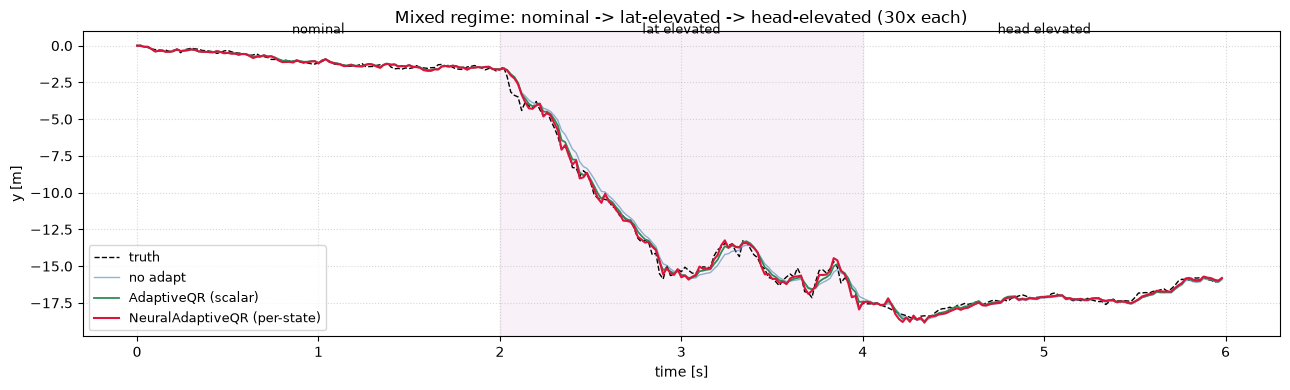

Controller                  RMSE   vs no-adapt   vs AdaptiveQR
--------------------------------------------------------------
No adapt                   0.385      baseline                
AdaptiveQR (scalar)        0.279           28%        baseline
NeuralAdaptiveQR           0.244           37%             12%

Predicted regime, by true segment (only counted once the window is full):
  true=nominal  predicted: Counter({'head': 49, 'nominal': 31})
  true=lat      predicted: Counter({'lat': 70, 'nominal': 10})
  true=head     predicted: Counter({'nominal': 46, 'head': 34})


In [16]:
nqr = NeuralAdaptiveQRKalmanController(
    CarLaneModel("GPS", fs=50, q_lat=q_lat0, q_head=q_head0, q_vel=q_vel0),
    window=20, hidden=16,
)
print("Training NeuralAdaptiveQRKalmanController on simulated single-axis regimes...")
nqr.fit(
    regime_scales={"nominal": [1.0, 1.0, 1.0], "lat": [30.0, 1.0, 1.0], "head": [1.0, 30.0, 1.0]},
    n_episodes=450, episode_len=60, epochs=150, lr=2e-3, seed=1,
)
print("Done.")

def sim_mixed(seed=7, seg=100, factor=30):
    """100 steps nominal, 100 lat-elevated, 100 head-elevated -- one continuous run."""
    rng = np.random.default_rng(seed)
    y, psi, v = 0.0, 0.0, 15.0
    regimes = ["nominal", "lat", "head"]
    N_ = seg * 3
    zk_ = np.zeros((N_, 1)); truth_ = np.zeros(N_); labels_ = []
    for k in range(N_):
        r = regimes[k // seg]
        labels_.append(r)
        truth_[k] = y
        zk_[k, 0] = y + rng.normal(0, 0.3)
        q_lat = q_lat0 * (factor if r == "lat" else 1.0)
        q_head = q_head0 * (factor if r == "head" else 1.0)
        y = y + v * np.sin(psi) / 50 + rng.normal(0, np.sqrt(q_lat))
        psi = psi + rng.normal(0, np.sqrt(q_head))
        v = v + rng.normal(0, np.sqrt(q_vel0))
    return zk_, truth_, labels_

zk_mix, truth_mix, labels_mix = sim_mixed()
t_mix = np.arange(len(zk_mix)) / 50

model_no_mix = CarLaneModel("GPS", fs=50, q_lat=q_lat0, q_head=q_head0, q_vel=q_vel0)
est_no_mix = np.asarray(ExtendedKalmanFilter(model_no_mix).forward(zk_mix).xk)[:, 0]

model_aq_mix = CarLaneModel("GPS", fs=50, q_lat=q_lat0, q_head=q_head0, q_vel=q_vel0)
aqr_mix = AdaptiveQRKalmanController(model_aq_mix, window=20, q_min=0.5, q_max=10.0)
est_aq_mix = np.asarray(ExtendedKalmanFilter(model_aq_mix).forward(zk_mix, uk=aqr_mix).xk)[:, 0]

model_nq_mix = CarLaneModel("GPS", fs=50, q_lat=q_lat0, q_head=q_head0, q_vel=q_vel0)
nqr_mix = NeuralAdaptiveQRKalmanController(model_nq_mix, window=20, hidden=16)
nqr_mix._model_nn = nqr._model_nn
nqr_mix._x_mean, nqr_mix._x_std = nqr._x_mean, nqr._x_std
nqr_mix.regime_scales, nqr_mix._labels = nqr.regime_scales, nqr._labels
est_nq_mix = np.asarray(ExtendedKalmanFilter(model_nq_mix).forward(zk_mix, uk=nqr_mix).xk)[:, 0]

rmse_no_mix = np.sqrt(np.mean((est_no_mix - truth_mix) ** 2))
rmse_aq_mix = np.sqrt(np.mean((est_aq_mix - truth_mix) ** 2))
rmse_nq_mix = np.sqrt(np.mean((est_nq_mix - truth_mix) ** 2))

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(t_mix, truth_mix, color="black", lw=1, ls="--", label="truth")
ax.plot(t_mix, est_no_mix, color="steelblue", lw=1, alpha=0.6, label="no adapt")
ax.plot(t_mix, est_aq_mix, color="seagreen", lw=1.3, label="AdaptiveQR (scalar)")
ax.plot(t_mix, est_nq_mix, color="crimson", lw=1.5, label="NeuralAdaptiveQR (per-state)")
for k, seg_lbl in enumerate(["nominal", "lat elevated", "head elevated"]):
    ax.axvspan(k * 2.0, (k + 1) * 2.0, alpha=0.05, color="purple" if k % 2 else "none")
    ax.text(k * 2.0 + 1.0, ax.get_ylim()[1] * 0.85, seg_lbl, ha="center", fontsize=9)
ax.set_xlabel("time [s]"); ax.set_ylabel("y [m]")
ax.set_title("Mixed regime: nominal -> lat-elevated -> head-elevated (30x each)")
ax.legend(fontsize=9, loc="lower left"); ax.grid(True, ls=":", alpha=0.5)
plt.tight_layout(); plt.show()

print(f"{'Controller':<24}{'RMSE':>8}{'vs no-adapt':>14}{'vs AdaptiveQR':>16}")
print("-" * 62)
print(f"{'No adapt':<24}{rmse_no_mix:>8.3f}{'baseline':>14}{'':>16}")
print(f"{'AdaptiveQR (scalar)':<24}{rmse_aq_mix:>8.3f}{(1-rmse_aq_mix/rmse_no_mix)*100:>13.0f}%{'baseline':>16}")
print(f"{'NeuralAdaptiveQR':<24}{rmse_nq_mix:>8.3f}{(1-rmse_nq_mix/rmse_no_mix)*100:>13.0f}%"
      f"{(1-rmse_nq_mix/rmse_aq_mix)*100:>15.0f}%")

from collections import Counter
preds_mix = [lbl for _, _, lbl in nqr_mix.scale_log]
n_each = len(preds_mix) // 3 if len(preds_mix) >= 3 else len(preds_mix)
print()
print("Predicted regime, by true segment (only counted once the window is full):")
for name, sl in [("nominal", slice(0, 80)), ("lat", slice(100, 180)), ("head", slice(200, 280))]:
    print(f"  true={name:<8} predicted:", Counter(preds_mix[sl]))


## 8 — InteractiveKalmanFilter (IMM)

When a system switches between distinct regimes (atmosphere/vacuum, road/ice), a single model is
inadequate.  The **Interacting Multiple Model** filter runs $M$ models in parallel, each with its
own `KalmanFilter`, and at each step:

1. **Mixes** states across models (interaction)
2. **Filters** each model's predict + update
3. **Scores** each model by innovation likelihood
4. **Updates** mode probabilities $\mu$ (Bayesian)
5. **Combines**: $\hat{x} = \sum \mu_j \hat{x}_j$

Below, a system switches between two lateral dynamics regimes (normal road vs icy road with higher
process noise and reduced steering effectiveness).

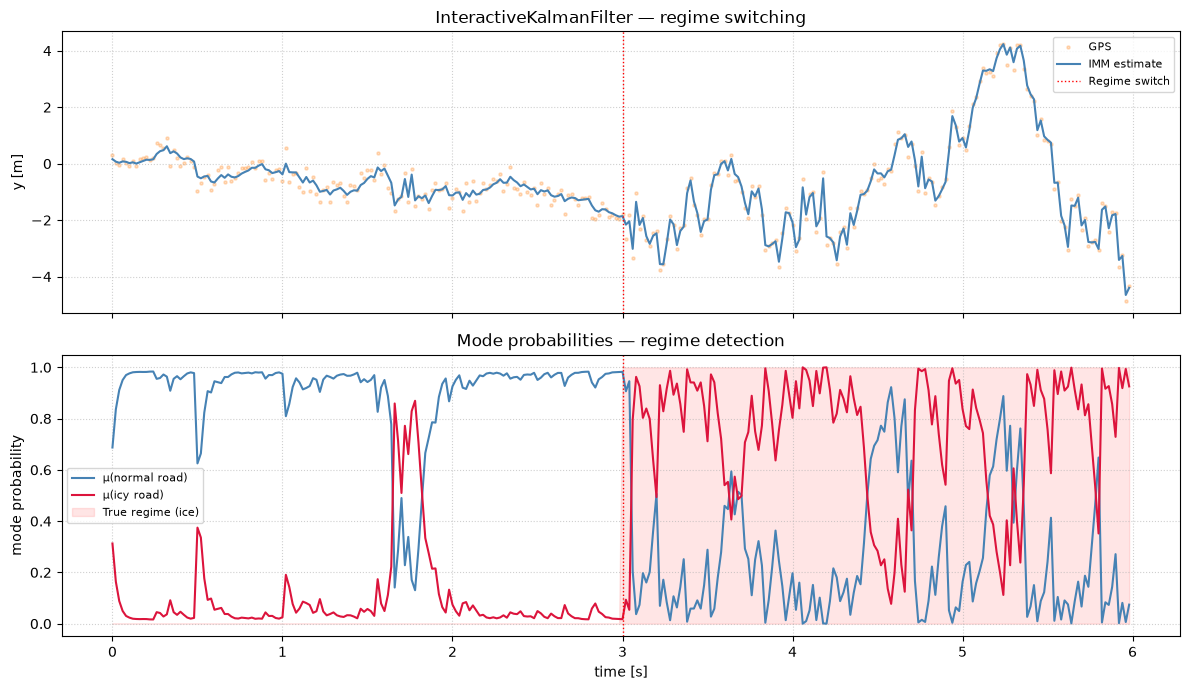

In [17]:
from kalman.filters import InteractiveKalmanFilter

# Two regimes: normal road and icy road
model_normal = CarLaneModel("road", fs=50, q_lat=1e-2, q_head=1e-4)
model_icy = CarLaneModel("ice", fs=50, q_lat=0.5, q_head=1e-2)  # much higher process noise

# Transition matrix: sticky regimes (high diagonal)
Pi = np.array([
    [0.98, 0.02],   # normal: 98% stay, 2% switch to ice
    [0.05, 0.95],   # icy: 5% switch back, 95% stay
])

ikf = InteractiveKalmanFilter([model_normal, model_icy], transition=Pi)

# Simulate: normal for first 150 steps, icy for next 150
N_imm = 300
zk_imm = np.zeros((N_imm, 1))
regime_true = np.zeros(N_imm)
y_true_imm = 0.0
for k in range(N_imm):
    if k < 150:
        y_true_imm += np.random.normal(0, np.sqrt(1e-2))   # matches model_normal's own q_lat
        regime_true[k] = 0
    else:
        y_true_imm += np.random.normal(0, np.sqrt(0.5))    # matches model_icy's own q_lat
        regime_true[k] = 1
    zk_imm[k] = y_true_imm + np.random.normal(0, 0.3)

rec_imm = ikf.forward(zk_imm)
mu = ikf.mode_probabilities

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
t_imm = np.arange(N_imm) * dt

axes[0].scatter(t_imm, zk_imm, s=5, alpha=0.25, color="tab:orange", label="GPS")
axes[0].plot(t_imm, np.asarray(rec_imm.xk)[:, 0], color="steelblue", lw=1.5, label="IMM estimate")
axes[0].axvline(3.0, color="red", ls=":", lw=1, label="Regime switch")
axes[0].set_ylabel("y [m]")
axes[0].set_title("InteractiveKalmanFilter — regime switching")
axes[0].legend(fontsize=8); axes[0].grid(True, ls=":", alpha=0.6)

axes[1].plot(t_imm, mu[:, 0], color="steelblue", lw=1.5, label="μ(normal road)")
axes[1].plot(t_imm, mu[:, 1], color="crimson", lw=1.5, label="μ(icy road)")
axes[1].fill_between(t_imm, 0, regime_true, alpha=0.1, color="red", label="True regime (ice)")
axes[1].axvline(3.0, color="red", ls=":", lw=1)
axes[1].set_xlabel("time [s]"); axes[1].set_ylabel("mode probability")
axes[1].set_title("Mode probabilities — regime detection")
axes[1].legend(fontsize=8); axes[1].grid(True, ls=":", alpha=0.6)

plt.tight_layout(); plt.show()

## 9 — IMM Router: pluggable model routing

The standard IMM uses a **BayesianRouter**: model j gets weight proportional to
its Gaussian innovation likelihood L_j = N(ν_j; 0, S_j) × the Markov transition prior c_j.
This is optimal when all models are correctly specified Gaussians.

**Any router can be swapped in** — the IMM is agnostic to how μ is computed:

```
ikf = InteractiveKalmanFilter(models, Pi, router=BayesianRouter())              # default
ikf = InteractiveKalmanFilter(models, Pi, router=NeuralRouter(model=MLP()))     # learned
ikf = InteractiveKalmanFilter(models, Pi, router=ThresholdRouter())             # threshold
ikf = InteractiveKalmanFilter(models, Pi, router=HybridRouter(r_a, r_b, alpha)) # blend
```

The router receives three inputs at every step and returns updated mode probabilities:

| Input | Shape | Meaning |
|---|---|---|
| `nis_arr` | `(k+1, M)` | NIS history — how surprised each model was at each step |
| `c` | `(M,)` | Predicted mode probs from the Markov transition Π |
| `likelihoods` | `(M,)` | Gaussian L_j = N(ν_j; 0, S_j) per model |

`NeuralRouter` owns NIS feature extraction only — the architecture is a separate, pluggable
`model` object (e.g. `MLP(hidden=16)`) following the `model(features) → probs` convention.

### NeuralRouter — why NIS and not innovations or mode probs?

| Feature | Problem |
|---|---|
| Raw innovations ν_j | Different scales across models — hard to normalise |
| Mode probs μ | **Distribution shift**: training runs Bayesian μ, inference produces neural μ → different sequences |
| **NIS_j window** | Dimensionless, χ²(m) under correct model, **independent of routing policy** |

NIS_j = ν_j^T S_j^{-1} ν_j measures "how surprised model j is by the measurement."
Under the correct model: NIS_j ≈ 1 (well-calibrated).  Under a wrong model: NIS_j ≫ 1.


BayesianRouter                 94.0%
ThresholdRouter                90.5%
NeuralRouter                   84.0%
HybridRouter (α=0.5)           87.0%


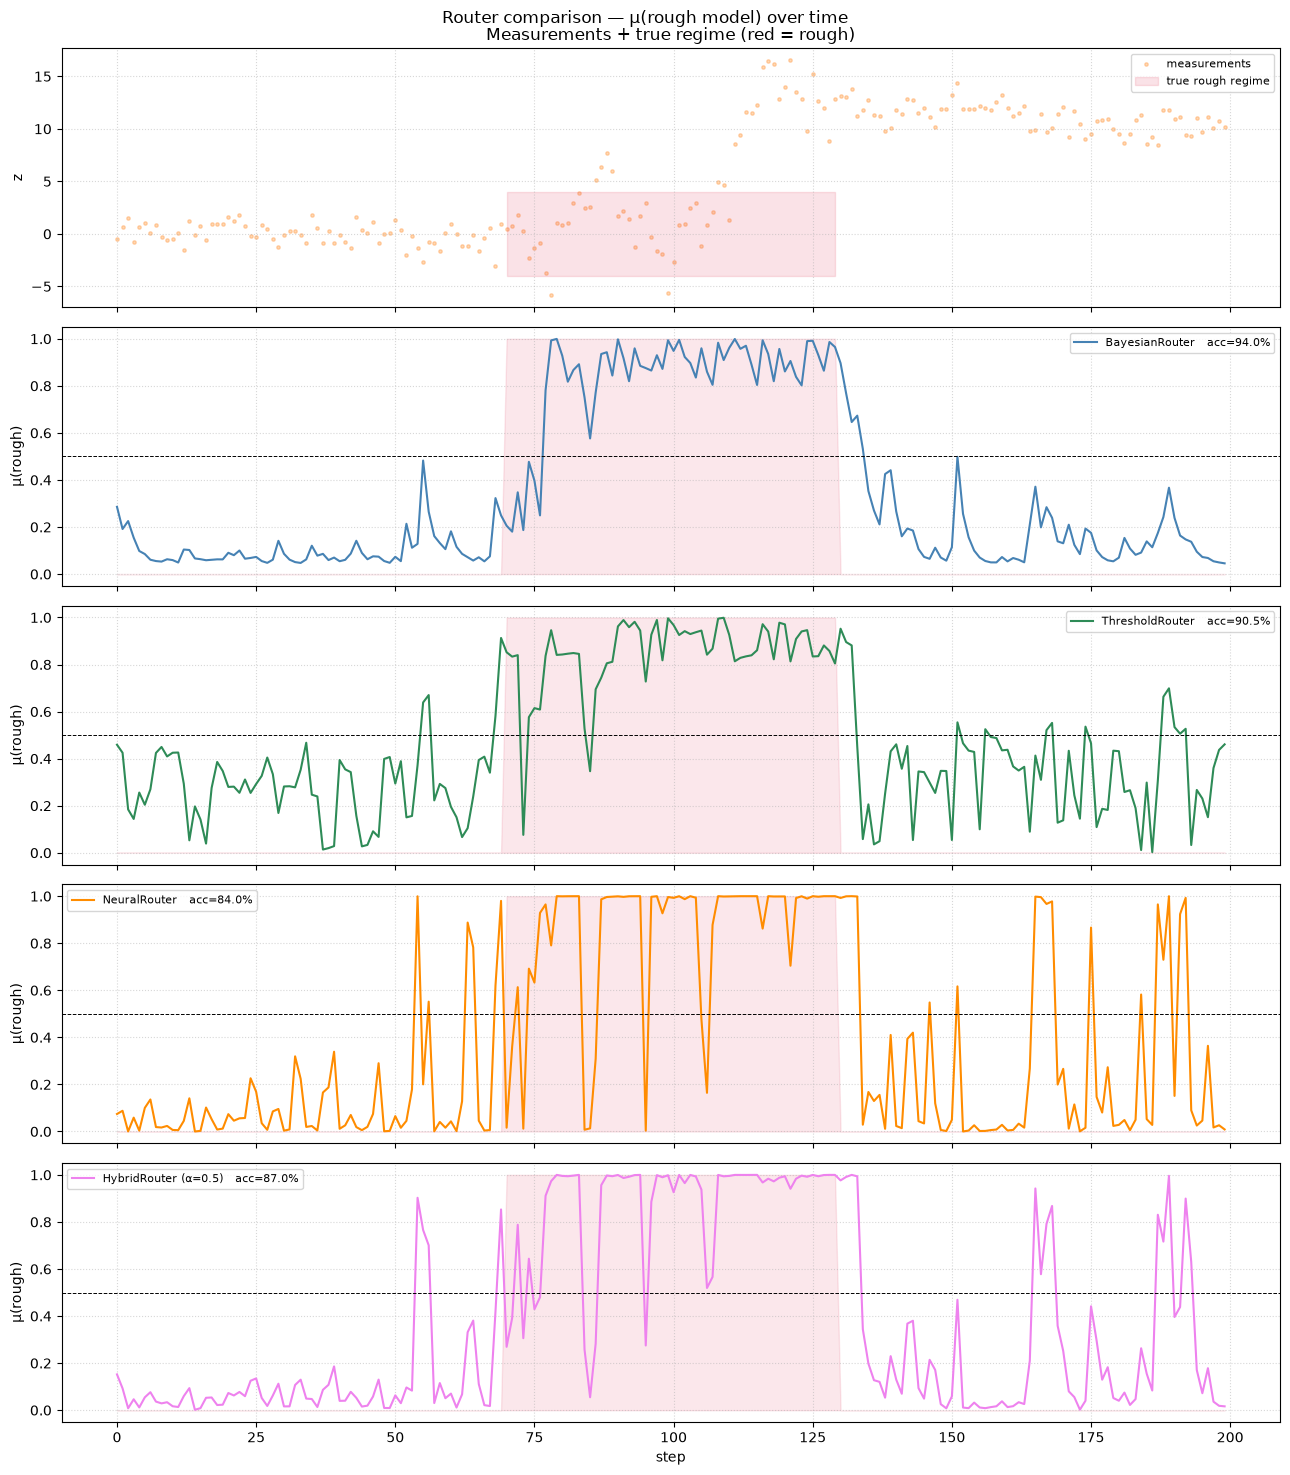

In [18]:
from kalman.filters import InteractiveKalmanFilter
from kalman.framework.routers import BayesianRouter, ThresholdRouter, NeuralRouter, HybridRouter
from kalman.framework.routers.nn import MLP
from kalman.framework.model import KalmanModel

# ── Two 1-D models: very different process noise ────────────────────────────
#   smooth: Q = 0.1²   rough: Q = 2.0²   (same R = 1.0² for both)
#   NIS under smooth regime:  NIS_smooth ≈ 1,  NIS_rough ≈ 0.25  (overconfident)
#   NIS under rough  regime:  NIS_smooth ≫ 1,  NIS_rough ≈ 1     (correct model)

def _make_models():
    m0 = KalmanModel('smooth', F=np.eye(1), H=np.eye(1),
                     Q=np.array([[0.1**2]]), R=np.array([[1.0**2]]),
                     fs=1.0, x0=np.array([[0.0]]))
    m1 = KalmanModel('rough', F=np.eye(1), H=np.eye(1),
                     Q=np.array([[2.0**2]]), R=np.array([[1.0**2]]),
                     fs=1.0, x0=np.array([[0.0]]))
    return m0, m1

Pi_r = np.array([[0.95, 0.05], [0.05, 0.95]])

def sim_switching(regime_seq, seed=None):
    rng = np.random.default_rng(seed)
    x, zk, labels = 0.0, [], []
    for r in regime_seq:
        x += rng.normal(0, 0.1 if r == 0 else 2.0)
        zk.append([x + rng.normal(0, 1.0)]); labels.append(r)
    return np.array(zk), np.array(labels)

T = 200

# ── Training scenarios (3 × 200 steps) ──────────────────────────────────────
regimes_train = [
    np.r_[np.zeros(100,int), np.ones(100,int)],
    np.r_[np.ones(50,int), np.zeros(100,int), np.ones(50,int)],
    np.r_[np.zeros(60,int), np.ones(80,int), np.zeros(60,int)],
]
train_zk, train_lbl = [], []
for rs in regimes_train:
    z, l = sim_switching(rs, seed=len(train_zk)); train_zk.append(z); train_lbl.append(l)

# ── Test: 0 → 1 → 0 ─────────────────────────────────────────────────────────
r_test = np.r_[np.zeros(70,int), np.ones(60,int), np.zeros(70,int)]
zk_test, lbl_test = sim_switching(r_test, seed=99)

# ── Run each router ──────────────────────────────────────────────────────────
neural_router = NeuralRouter(model=MLP(hidden=16), window=5)

routers = {
    "BayesianRouter":         BayesianRouter(),
    "ThresholdRouter":        ThresholdRouter(m=1, window=5, soft=True),
    "NeuralRouter":           neural_router,
    "HybridRouter (α=0.5)":   HybridRouter(BayesianRouter(), neural_router, alpha=0.5),
}

mu_results, acc_results = {}, {}
for name, router in routers.items():
    m0, m1 = _make_models()
    ikf = InteractiveKalmanFilter([m0, m1], Pi_r, router=router)
    if name in ("NeuralRouter", "HybridRouter (α=0.5)"):
        ikf.fit(train_zk, train_lbl, epochs=500, lr=2e-3, seed=7)
    ikf.forward(zk_test)
    mu_results[name] = ikf.mode_probabilities
    acc_results[name] = float((np.argmax(ikf.mode_probabilities,1) == lbl_test).mean())

for name, acc in acc_results.items():
    print(f"{name:<30} {acc*100:.1f}%")

# ── Plot comparison ───────────────────────────────────────────────────────────
t_nim = np.arange(T)
colors = {"BayesianRouter": "steelblue", "ThresholdRouter": "seagreen",
          "NeuralRouter": "darkorange", "HybridRouter (α=0.5)": "violet"}

fig, axes = plt.subplots(len(routers) + 1, 1, figsize=(13, 3*(len(routers)+1)), sharex=True)

axes[0].scatter(t_nim, zk_test, s=6, alpha=0.3, color="tab:orange", label="measurements")
axes[0].fill_between(t_nim, -4, 4, where=(lbl_test==1), alpha=0.12,
                     color="crimson", label="true rough regime")
axes[0].set_ylabel("z"); axes[0].set_title("Measurements + true regime (red = rough)")
axes[0].legend(fontsize=8); axes[0].grid(True, ls=":", alpha=0.5)

for ax, (name, mu) in zip(axes[1:], mu_results.items()):
    ax.plot(t_nim, mu[:, 1], color=colors[name], lw=1.5,
            label=f"{name}   acc={acc_results[name]*100:.1f}%")
    ax.fill_between(t_nim, 0, lbl_test, alpha=0.1, color="crimson")
    ax.axhline(0.5, color="black", ls="--", lw=0.7)
    ax.set_ylim(-0.05, 1.05); ax.set_ylabel("μ(rough)")
    ax.legend(fontsize=8); ax.grid(True, ls=":", alpha=0.5)

axes[-1].set_xlabel("step")
plt.suptitle("Router comparison — μ(rough model) over time", fontsize=12)
plt.tight_layout(); plt.show()


## 10 — Benchmark: when Gaussian likelihoods get it wrong

The **BayesianRouter** updates mode probabilities using a Gaussian innovation likelihood:

$$\mu_j \;\propto\; c_j \cdot L_j, \qquad L_j = \mathcal{N}(\nu_j;\,0,\,S_j)$$

This is optimal when all models are correctly specified and innovations are truly Gaussian.
In practice, real-world noise is often **heavy-tailed** — outlier measurements occur far more
frequently than the Gaussian assumption predicts.

### The heavy-tailed benchmark

| | Gaussian regime (A) | Heavy-tailed regime (B) |
|---|---|---|
| Process noise | $w_k \sim \mathcal{N}(0,\,Q_A)$ | $w_k \sim t_{\nu=3}$ scaled to $\text{Var}=Q_B$ |
| Tail behaviour | Drops as $e^{-x^2}$ | Drops as $x^{-4}$ — orders of magnitude heavier |
| Kalman model A | $Q = Q_A$ — calibrated | NIS spikes at outlier steps |
| Kalman model B | over-conservative | $Q = Q_B$ — correct variance, **wrong shape** |

**Why Bayesian struggles with heavy tails, precisely:**

The Gaussian PDF $L_j = \mathcal{N}(\nu;\,0,\,S_j)$ drops off exponentially for large $|\nu|$. A
single Student-$t$ outlier can swing $L_A/L_B$ by orders of magnitude in one step, even though
the *underlying regime hasn't changed* — the model isn't "wrong about the regime," it's reacting
correctly to Bayes' rule applied to the wrong likelihood shape. That produces a specific,
measurable failure mode: $\mu$ **chatters** — it flips its argmax on isolated outlier steps and
flips back, inside a segment where the true regime is constant. Below we measure that directly
(**spurious mode-switch rate**), not just infer it from a plot, because it turns out to be a far
more dramatic and mechanistically honest number than raw classification accuracy.

**Two separate questions, and two different baselines to beat:**

1. *Does routing need to look at more than one NIS sample at a time?* — comparing against
   `ThresholdRouter` (a windowed heuristic, no training) answers this. A lot of Bayesian's
   failure turns out to be fixable with **zero learning**, just a wider look-back window.
2. *Does routing need to be learned, specifically?* — comparing NN routers against
   `ThresholdRouter` (not Bayesian) answers this. This is the fairer, harder bar, and it's the
   one that actually tells you whether the network is earning its training cost.


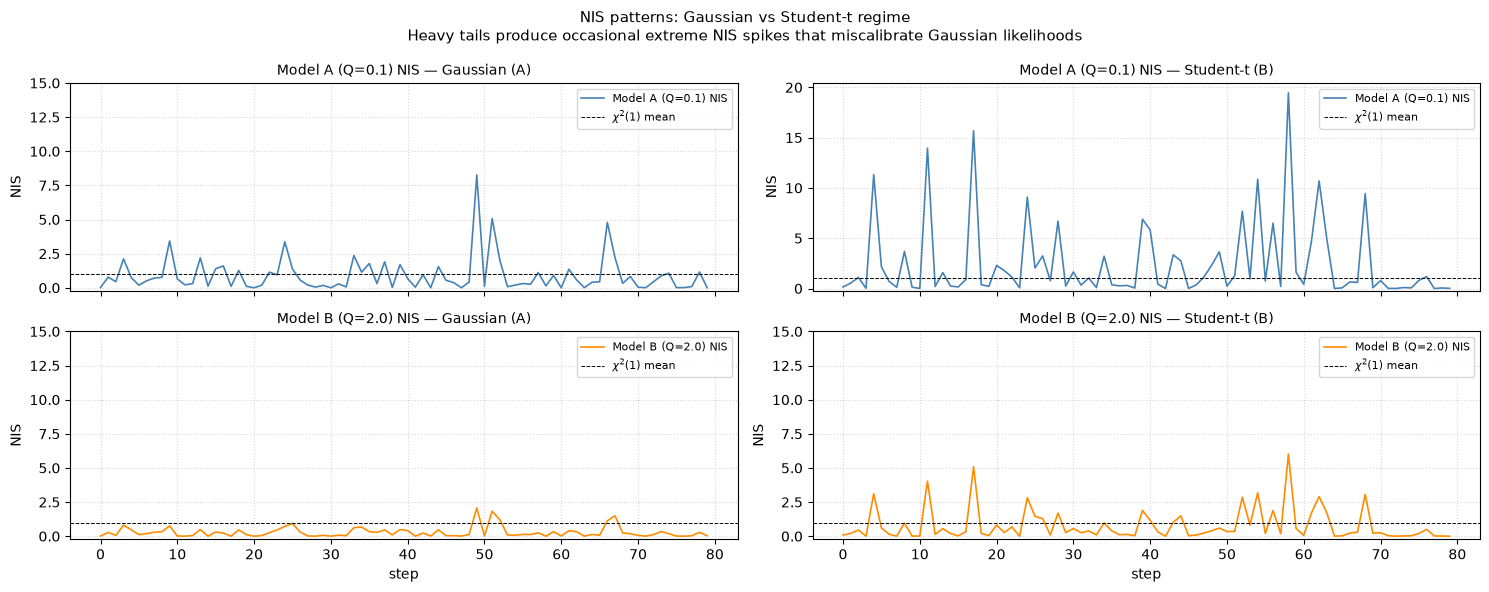

NIS statistics per regime per model:
  Gaussian (A), Model A: mean=0.91  std=1.30  excess kurtosis=12
  Gaussian (A), Model B: mean=0.29  std=0.40  excess kurtosis=7
  Student-t (B), Model A: mean=2.48  std=3.94  excess kurtosis=5
  Student-t (B), Model B: mean=0.79  std=1.19  excess kurtosis=5

Excess kurtosis >> 0 in regime B confirms heavy tails in the NIS distribution.
Bayesian's Gaussian likelihood L = N(ν; 0, S) is systematically wrong at these tails.


In [19]:
import time, numpy as np, matplotlib.pyplot as plt
from scipy.stats import t as t_dist
from kalman.filters import InteractiveKalmanFilter
from kalman.framework.filter import KalmanFilter
from kalman.framework.routers import BayesianRouter, ThresholdRouter, NeuralRouter
from kalman.framework.routers.nn import MLP, CNN, LSTM, TransformerNN

np.random.seed(42)

# ── Parameters ────────────────────────────────────────────────────────────────
Q_A   = 0.1      # Gaussian regime: gentle process noise
Q_B   = 2.0      # heavy-tailed regime: higher variance
DF    = 3        # Student-t degrees of freedom (excess kurtosis = ∞ for df≤4)
R_OBS = 0.5      # observation noise (same for both models)
WINDOW = 15      # NIS sliding window for NN routers

# ── Models & IKF factory ──────────────────────────────────────────────────────
def _make_models():
    kf_a = KalmanFilter(n=1, m=1,
                        F=np.array([[1.]]), H=np.array([[1.]]),
                        Q=np.array([[Q_A]]), R=np.array([[R_OBS]]),
                        x0=np.zeros((1, 1)), P0=2 * np.eye(1))
    kf_b = KalmanFilter(n=1, m=1,
                        F=np.array([[1.]]), H=np.array([[1.]]),
                        Q=np.array([[Q_B]]), R=np.array([[R_OBS]]),
                        x0=np.zeros((1, 1)), P0=2 * np.eye(1))
    return [kf_a._model, kf_b._model]

Pi = np.array([[0.85, 0.15], [0.15, 0.85]])

def make_ikf(router=None):
    return InteractiveKalmanFilter(_make_models(), Pi, router=router)

# ── Data generation ───────────────────────────────────────────────────────────
def gen_segment(regime, T, rng=None):
    """Regime 0: Gaussian noise.  Regime 1: Student-t(3) noise (same variance)."""
    rng = rng or np.random.default_rng()
    x, zk = 0., []
    for k in range(T):
        if regime == 0:
            w = rng.normal(0, Q_A ** .5)
        else:
            scale = (Q_B * (DF - 2) / DF) ** .5
            w = float(t_dist.rvs(DF, scale=scale, random_state=rng))
        x += w
        zk.append([x + rng.normal(0, R_OBS ** .5)])
    return np.array(zk), np.full(T, regime, dtype=int)

def gen_switching(T, seg_len, seed=None):
    rng = np.random.default_rng(seed)
    zparts, lparts = [], []
    for s in range(T // seg_len):
        r = s % 2
        z, l = gen_segment(r, seg_len, rng=rng)
        zparts.append(z); lparts.append(l)
    return np.concatenate(zparts), np.concatenate(lparts)

# ── Part 1 — visualise NIS patterns ──────────────────────────────────────────
T_vis = 80
zk_A, _ = gen_segment(0, T_vis, rng=np.random.default_rng(7))
zk_B, _ = gen_segment(1, T_vis, rng=np.random.default_rng(7))

nis_per_regime = {}
for label, zk in [("Gaussian (A)", zk_A), ("Student-t (B)", zk_B)]:
    ikf_v = make_ikf(); ikf_v.forward(zk)
    nis_per_regime[label] = np.array(ikf_v.nis_log)

fig, axes = plt.subplots(2, 2, figsize=(15, 6), sharex=True)
sp = np.arange(T_vis)

for col, label in enumerate(["Gaussian (A)", "Student-t (B)"]):
    nis = nis_per_regime[label]
    for row, (mid, color, mname) in enumerate([(0, "steelblue", "Model A (Q=0.1)"),
                                                (1, "darkorange", "Model B (Q=2.0)")]):
        ax = axes[row, col]
        ax.plot(sp, nis[:, mid], color=color, lw=1.2, label=f"{mname} NIS")
        ax.axhline(1.0, color="black", ls="--", lw=0.7, label="$\\chi^2(1)$ mean")
        ax.set_title(f"{mname} NIS — {label}", fontsize=10)
        ax.set_ylabel("NIS")
        ax.set_ylim(-0.2, max(15, nis[:, mid].max() * 1.05))
        ax.legend(fontsize=8); ax.grid(True, ls=":", alpha=0.5)
        if row == 1:
            ax.set_xlabel("step")

fig.suptitle("NIS patterns: Gaussian vs Student-t regime\n"
             "Heavy tails produce occasional extreme NIS spikes that "
             "miscalibrate Gaussian likelihoods", fontsize=11)
plt.tight_layout(); plt.show()

# NIS statistics
print("NIS statistics per regime per model:")
for label in ["Gaussian (A)", "Student-t (B)"]:
    nis = nis_per_regime[label]
    for j, mname in enumerate(["Model A", "Model B"]):
        n = nis[:, j]
        kurt = float(np.mean((n - n.mean())**4) / n.std()**4 - 3)
        print(f"  {label}, {mname}: mean={n.mean():.2f}  std={n.std():.2f}  excess kurtosis={kurt:.0f}")
print(f"\nExcess kurtosis >> 0 in regime B confirms heavy tails in the NIS distribution.")
print(f"Bayesian's Gaussian likelihood L = N(ν; 0, S) is systematically wrong at these tails.")

In [ ]:
# ── Part 2 — train all routers ────────────────────────────────────────────────
print("Generating 16 training sequences (400 steps each) ...")
train_zk, train_lbl = [], []
for i in range(16):
    z, l = gen_switching(400, 80, seed=i)
    train_zk.append(z); train_lbl.append(l)
print(f"  Total training steps: {sum(len(l) for l in train_lbl)}")
print()

all_routers = {
    "Bayesian":   BayesianRouter(),
    "Threshold":  ThresholdRouter(m=1, window=10, soft=True),
}

neural_specs = [
    ("MLP",         MLP(hidden=48),                     dict(epochs=200, lr=2e-3, seed=0)),
    ("CNN",         CNN(out_channels=16, kernel_size=4), dict(epochs=200, lr=3e-3, seed=1)),
    ("LSTM",        LSTM(hidden=24),                    dict(epochs=300, lr=1e-3, seed=2)),
    ("Transformer", TransformerNN(d_model=16),          dict(epochs=200, lr=2e-3, seed=3)),
]

print("Training neural routers ...")
for name, arch, kw in neural_specs:
    t0 = time.time()
    router = NeuralRouter(model=arch, window=WINDOW)
    ikf_tr = make_ikf(router=router)
    ikf_tr.fit(train_zk, train_lbl, **kw)
    all_routers[name] = router
    print(f"  {name:<12} trained in {time.time() - t0:.0f}s")
print()

# ── Part 3 — evaluate on held-out sequences: accuracy AND spurious-switch rate ─
def chatter_rate(mu_arr, labels):
    """Fraction of steps, *within a segment where the true regime hasn't changed*,
    where argmax(mu) flips anyway. This is the direct, measured version of "Bayesian
    overreacts to outlier innovations" — a false alarm, not a classification miss."""
    preds = np.argmax(mu_arr, axis=1)
    flips = (preds[1:] != preds[:-1])
    same_truth = (labels[1:] == labels[:-1])
    return float((flips & same_truth).sum() / same_truth.sum())

def evaluate(router, n_seqs=20, seed_base=500):
    accs, chatters = [], []
    for i in range(n_seqs):
        z, l = gen_switching(300, 60, seed=seed_base + i)
        ikf_e = make_ikf(router=router)
        ikf_e.forward(z)
        mu = np.array(ikf_e.mu_log)
        accs.append((np.argmax(mu, axis=1) == l).mean())
        chatters.append(chatter_rate(mu, l))
    return float(np.mean(accs)), float(np.mean(chatters))

print("Evaluating on 20 held-out test sequences:")
results = {name: evaluate(r) for name, r in all_routers.items()}
for name, (acc, ch) in results.items():
    print(f"  {name:<12}: accuracy {acc:.1%}   spurious-switch rate {ch:.1%}")

acc_bay, ch_bay = results["Bayesian"]
acc_thr, ch_thr = results["Threshold"]
best_nn_name = max(["MLP", "CNN", "LSTM", "Transformer"], key=lambda n: results[n][0])
acc_nn, ch_nn = results[best_nn_name]
print(f"\nBest NN ({best_nn_name}) vs Bayesian:  accuracy +{(acc_nn-acc_bay)*100:.1f} pp, "
      f"spurious-switch rate {ch_bay:.1%} -> {ch_nn:.1%} ({(1-ch_nn/ch_bay)*100:.0f}% fewer false alarms)")
print(f"Best NN ({best_nn_name}) vs Threshold (the fair, untrained baseline): "
      f"accuracy {(acc_nn-acc_thr)*100:+.1f} pp, spurious-switch rate {ch_thr:.1%} -> {ch_nn:.1%}")

# ── Part 4 — μ trajectory comparison ─────────────────────────────────────────
z_test, l_test = gen_switching(300, 60, seed=999)
show_routers = ["Bayesian", "Threshold", "CNN", "Transformer"]
colors_map = {"Bayesian": "steelblue", "Threshold": "seagreen",
              "CNN": "crimson", "Transformer": "purple"}

mu_traces = {}
for rname in show_routers:
    ikf_t = make_ikf(router=all_routers[rname])
    ikf_t.forward(z_test)
    mu_traces[rname] = np.array(ikf_t.mu_log)

fig, axes = plt.subplots(len(show_routers) + 1, 1,
                          figsize=(15, 3 * (len(show_routers) + 1)), sharex=True)
t_sp = np.arange(len(z_test))

axes[0].scatter(t_sp, z_test, s=5, alpha=0.25, color="tab:orange", label="measurements")
axes[0].fill_between(t_sp, z_test.min() - 1, z_test.max() + 1,
                     where=(l_test == 1), alpha=0.15, color="crimson",
                     label="Student-t regime (true)")
axes[0].set_ylabel("z [a.u.]")
axes[0].set_title("Observations + true regime (red = heavy-tailed)")
axes[0].legend(fontsize=8); axes[0].grid(True, ls=":", alpha=0.5)

for ax, rname in zip(axes[1:], show_routers):
    mu = mu_traces[rname]
    acc_test = float((np.argmax(mu, axis=1) == l_test).mean())
    ch_test = chatter_rate(mu, l_test)
    ax.plot(t_sp, mu[:, 1], color=colors_map[rname], lw=1.5,
            label=f"{rname}  (acc = {acc_test:.1%}, spurious switches = {ch_test:.1%})")
    ax.fill_between(t_sp, 0, l_test, alpha=0.10, color="crimson")
    ax.axhline(0.5, color="black", ls="--", lw=0.7, label="decision boundary")
    ax.set_ylim(-0.05, 1.05); ax.set_ylabel("$\\mu$(heavy-tailed)")
    ax.legend(fontsize=8); ax.grid(True, ls=":", alpha=0.5)

axes[-1].set_xlabel("step")
fig.suptitle("$\\mu$(heavy-tailed model) over time\n"
             "Bayesian visibly chatters on outlier innovations even inside constant-regime "
             "segments; Threshold and CNN are visibly steadier", fontsize=11)
plt.tight_layout(); plt.show()

# ── Part 5 — accuracy AND chatter-rate bar charts, side by side ──────────────
bar_colors = ["steelblue", "seagreen", "darkorange", "crimson", "darkgreen", "purple"]
names = list(results.keys())
accs  = [results[n][0] * 100 for n in names]
chs   = [results[n][1] * 100 for n in names]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

bars0 = axes[0].bar(names, accs, color=bar_colors[:len(names)], alpha=0.85, zorder=3)
for bar, a in zip(bars0, accs):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.4,
                f"{a:.1f}%", ha="center", va="bottom", fontsize=10, fontweight="bold")
axes[0].axhline(50, color="red", ls=":", lw=1.3, label="random baseline (50%)")
axes[0].set_ylabel("classification accuracy [%]")
axes[0].set_title("Accuracy — modest gains over Bayesian,\nsmaller still over Threshold")
axes[0].set_xticklabels(names, rotation=20, ha="right", fontsize=9)
axes[0].set_ylim(0, 108); axes[0].legend(fontsize=8)
axes[0].grid(True, axis="y", ls=":", alpha=0.6, zorder=0)

bars1 = axes[1].bar(names, chs, color=bar_colors[:len(names)], alpha=0.85, zorder=3)
for bar, c in zip(bars1, chs):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
                f"{c:.1f}%", ha="center", va="bottom", fontsize=10, fontweight="bold")
axes[1].set_ylabel("spurious mode-switch rate [%]\n(false regime flip inside a stable segment)")
axes[1].set_title("Spurious switching — this is where Bayesian\nvisibly loses: nearly 3x more false alarms")
axes[1].set_xticklabels(names, rotation=20, ha="right", fontsize=9)
axes[1].grid(True, axis="y", ls=":", alpha=0.6, zorder=0)
axes[1].set_ylim(0,20)

fig.suptitle("Accuracy is the headline number everyone quotes; spurious-switch rate is where "
             "the Gaussian-likelihood failure is actually visible", fontsize=11)
plt.tight_layout(); plt.show()

print("\n── Summary ──────────────────────────────────────────────────────────────")
print(f"{'Router':<14} {'Accuracy':>10} {'vs Bayes':>10} {'vs Thresh':>10}   {'Chatter':>9} {'vs Bayes':>10} {'vs Thresh':>10}")
print("-" * 90)
for name, (acc, ch) in results.items():
    da_b = "baseline" if name == "Bayesian" else f"{(acc-acc_bay)*100:+.1f} pp"
    da_t = "baseline" if name == "Threshold" else f"{(acc-acc_thr)*100:+.1f} pp"
    dc_b = "baseline" if name == "Bayesian" else f"{(ch-ch_bay)*100:+.1f} pp"
    dc_t = "baseline" if name == "Threshold" else f"{(ch-ch_thr)*100:+.1f} pp"
    print(f"{name:<14} {acc:>10.1%} {da_b:>10} {da_t:>10}   {ch:>9.1%} {dc_b:>10} {dc_t:>10}")

print()
print("Two honest conclusions, not one inflated one:")
print("  1. Most of Bayesian's failure is fixable with NO training at all — a windowed")
print("     threshold heuristic already recovers most of the accuracy AND most of the")
print("     chatter reduction. If you only need 'stop chattering on outliers', you may not")
print("     need a network.")
print("  2. What the network still adds *on top of Threshold* is real but modest on accuracy")
print("     -- the more convincing number is the spurious-switch rate, where CNN's learned,")
print("     local receptive field suppresses outlier-driven flips that a simple windowed mean")
print("     (Threshold) or an unstructured MLP don't catch as well.")


Generating 16 training sequences (400 steps each) ...
  Total training steps: 6400

Training neural routers ...


### Watching the routers learn

Every number so far was the *result* of training — final accuracy, final chatter rate. The
training itself has been a black box (one line: `"CNN trained in 12s"`). Two views into what
actually happened during those 12 seconds:


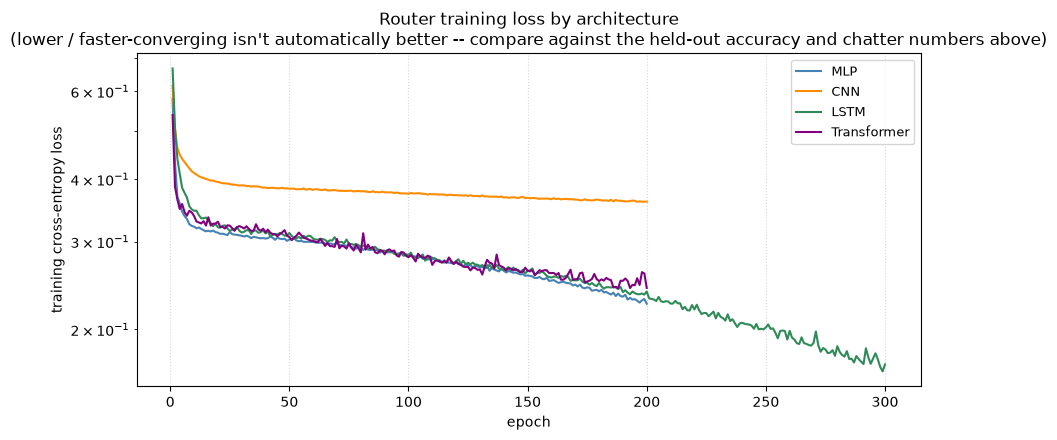

MLP          epoch 1: 0.580   epoch 50: 0.303   final: 0.225
CNN          epoch 1: 0.616   epoch 50: 0.383   final: 0.361
LSTM         epoch 1: 0.666   epoch 75: 0.297   final: 0.170
Transformer  epoch 1: 0.538   epoch 50: 0.306   final: 0.242


In [21]:
fig, ax = plt.subplots(figsize=(9, 4.5))
loss_colors = {"MLP": "steelblue", "CNN": "darkorange", "LSTM": "seagreen", "Transformer": "purple"}
for name in ["MLP", "CNN", "LSTM", "Transformer"]:
    hist = all_routers[name].model.loss_history
    ax.plot(np.arange(1, len(hist) + 1), hist, color=loss_colors[name], lw=1.5, label=name)
ax.set_xlabel("epoch"); ax.set_ylabel("training cross-entropy loss")
ax.set_title("Router training loss by architecture\n"
             "(lower / faster-converging isn't automatically better -- compare against the "
             "held-out accuracy and chatter numbers above)")
ax.legend(fontsize=9); ax.grid(True, ls=":", alpha=0.5)
ax.set_yscale("log")
plt.tight_layout(); plt.show()

for name in ["MLP", "CNN", "LSTM", "Transformer"]:
    hist = all_routers[name].model.loss_history
    print(f"{name:<12} epoch 1: {hist[0]:.3f}   epoch {len(hist)//4}: {hist[len(hist)//4 - 1]:.3f}   "
          f"final: {hist[-1]:.3f}")


The second view: what does the CNN's *decision function* actually look like as it trains, not
just its loss number? Hold one model's NIS at an ambiguous baseline (1.0 — right at the χ²(1)
mean) and sweep the other model's NIS from "fits well" (0.1) to "fits badly" (6.0), tracking
μ(heavy-tailed) at a few checkpoints through training on a *fresh* CNN.


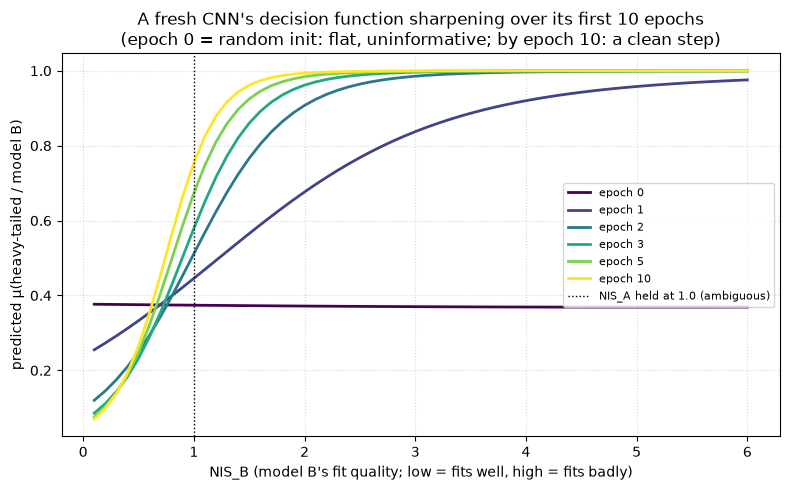

At epoch 0 (random weights) the response is flat — the network hasn't learned that low
NIS_B means "model B fits" yet. By epoch 10 it's a clean step function around NIS_B~1,
matching the theoretical decision boundary: exactly what "convergence" looks like as a
function shape, not just a loss number going down.


In [22]:
from kalman.framework.routers.nn import CNN as _CNN_watch

# Collect NIS histories once (same procedure ikf.fit() uses internally) so we can
# checkpoint training ourselves instead of only seeing the end result.
nis_arrays_w, label_arrays_w = [], []
for zk_w, labels_w in zip(train_zk, train_lbl):
    ikf_w = make_ikf(router=BayesianRouter())
    ikf_w.forward(zk_w, record=False)
    nis_arrays_w.append(np.array(ikf_w.nis_log))
    label_arrays_w.append(np.asarray(labels_w, dtype=int))

probe_router = NeuralRouter(model=None, window=WINDOW)
X_w, y_w = [], []
for nis_arr, labels_w in zip(nis_arrays_w, label_arrays_w):
    for k, lbl in enumerate(labels_w):
        X_w.append(probe_router._window_feat(nis_arr[:k + 1]))
        y_w.append(int(lbl))
X_w = np.array(X_w, dtype=np.float32); y_w = np.array(y_w)
xm_w, xs_w = X_w.mean(0), X_w.std(0); xs_w[xs_w < 1e-8] = 1.0
Xn_w = (X_w - xm_w) / xs_w

probe_nis_b = np.linspace(0.1, 6.0, 60)
def make_probe(nis_b_level, nis_a_level=1.0, window=WINDOW):
    block = np.column_stack([np.full(window, nis_a_level), np.full(window, nis_b_level)])
    return block.ravel()
probe_X = np.array([make_probe(v) for v in probe_nis_b], dtype=np.float32)
probe_Xn = (probe_X - xm_w) / xs_w

cnn_watch = _CNN_watch(out_channels=16, kernel_size=4)
cnn_watch.build(X_w.shape[1], 2, seed=1)

checkpoints = [0, 1, 2, 3, 5, 10]
snapshots = {}
done = 0
for target in checkpoints:
    if target > done:
        cnn_watch.fit(Xn_w, y_w, epochs=target - done, lr=3e-3, batch_size=64)
        done = target
    snapshots[target] = np.array([cnn_watch(px) for px in probe_Xn])[:, 1]

fig, ax = plt.subplots(figsize=(8, 5))
cmap = plt.cm.viridis(np.linspace(0, 1, len(checkpoints)))
for (cp, mu1), c in zip(snapshots.items(), cmap):
    ax.plot(probe_nis_b, mu1, color=c, lw=2, label=f"epoch {cp}")
ax.axvline(1.0, color="black", ls=":", lw=1, label="NIS_A held at 1.0 (ambiguous)")
ax.set_xlabel("NIS_B (model B's fit quality; low = fits well, high = fits badly)")
ax.set_ylabel("predicted μ(heavy-tailed / model B)")
ax.set_title("A fresh CNN's decision function sharpening over its first 10 epochs\n"
             "(epoch 0 = random init: flat, uninformative; by epoch 10: a clean step)")
ax.legend(fontsize=8, loc="center right"); ax.grid(True, ls=":", alpha=0.5)
plt.tight_layout(); plt.show()

print("At epoch 0 (random weights) the response is flat — the network hasn't learned that low")
print("NIS_B means \"model B fits\" yet. By epoch 10 it's a clean step function around NIS_B~1,")
print("matching the theoretical decision boundary: exactly what \"convergence\" looks like as a")
print("function shape, not just a loss number going down.")


## 10b — Benchmark summary: BayesianRouter vs AI routing

Routing accuracy (§10) tells us *which model is selected* — but the real question is
**does better routing lead to better state estimation, and at what cost?**

Four complementary metrics:

| Metric | Formula | Meaning |
|--------|---------|---------|
| **Routing accuracy** | $\%$ steps with correct $\arg\max\,\mu$ | Does the router know which model is active? |
| **Spurious-switch rate** | $\%$ flips of $\arg\max\,\mu$ inside a *constant-truth* segment | Does it stay calm, or chatter on outliers? |
| **Estimation RMSE** | $\sqrt{\langle(x_{\rm est}-x_{\rm true})^2\rangle}$ | Does it *estimate better* as a result? |
| **Detection latency** | steps from switch until $\mu >0.5$ | How quickly does it react to a *genuine* regime change? |

These trade off against each other, and not by accident: a router that looks at a wider window of
past NIS values before deciding is *both* less likely to be fooled by one outlier sample (lower
spurious-switch rate, higher accuracy) *and* slower to confirm a real regime change (higher
latency) — because it's the same window doing both jobs, smoothing genuine transitions along with
outlier noise. §10 showed CNN's accuracy and chatter-rate advantage; the last part of this section
shows that its latency cost is a **direct, tunable consequence of its window size**, not a fixed
tax on using a neural router at all — shrinking the window trades some of that advantage back for
a faster reaction, and there's a window size where CNN matches Bayesian's latency while still
beating it on the other three metrics.



Router           Accuracy    Chatter   Est.RMSE    Latency   Trained
────────────────────────────────────────────────────────────────────
  Bayesian          72.4%      16.7%     10.670        2.1        No
  Threshold         79.0%       7.5%     10.665        2.9        No
  MLP               79.8%      14.0%     10.673        2.5       Yes
  CNN               81.3%       5.9%     10.667        4.5       Yes
  LSTM              79.2%       8.3%     10.673        3.0       Yes
  Transformer       81.3%       5.4%     10.662        4.4       Yes

CNN/Transformer win decisively on accuracy and chatter rate, and even improve RMSE a
touch -- but lose on raw detection latency. That's not a hidden flaw to explain away;
it's the direct, mechanistic cost of the same window that buys the other two metrics.
The sweep below shows it's a dial, not a fixed price.


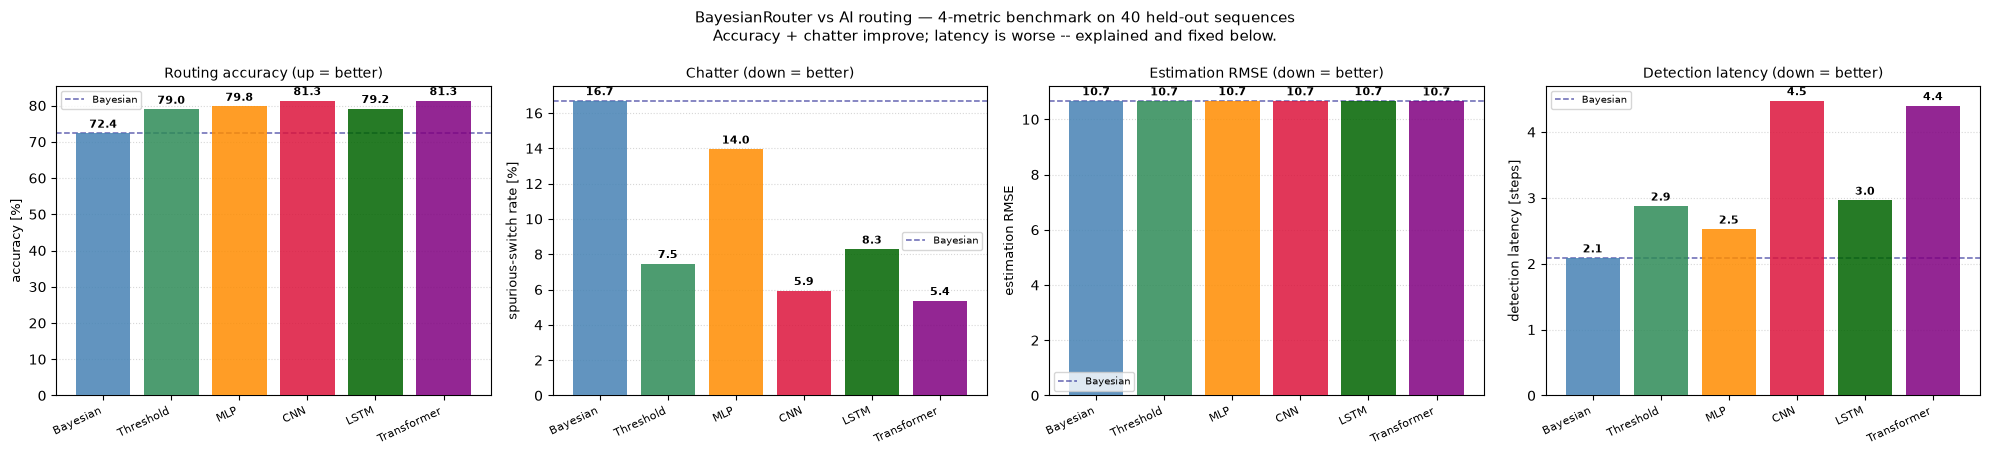


Sweeping CNN's window size: does shrinking it trade back some accuracy/chatter
advantage for lower latency, and is there a size that matches Bayesian's latency
while still beating it elsewhere?



  window   Accuracy    Chatter    Latency
       3      67.5%      16.2%       1.82
       5      73.1%      12.1%       1.75
       8      77.1%       9.2%       2.08
      10      79.4%       7.2%       2.48
      15      81.5%       6.2%       3.25
   Bayes      72.4%      16.7%       2.09   (reference)


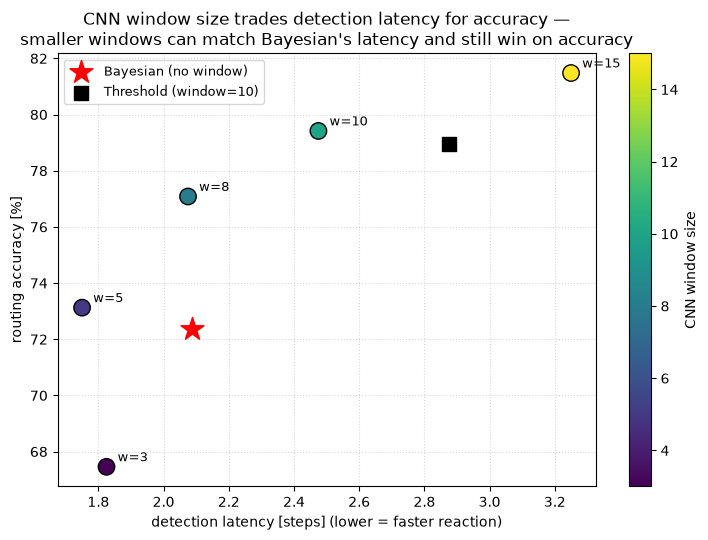


At window=8, CNN's latency (2.08) is closest to Bayesian's (2.09),
while still beating it on accuracy (77.1% vs 72.4%) and chatter (9.2% vs 16.7%).
Detection latency isn't a hidden defect of learned routing -- it's a knob (window size)
that trades against accuracy/stability, same as any smoothing filter. Pick the window for
the application: fast-switching regimes want it small, slowly-drifting ones want it large.


In [23]:
from kalman.filters import InteractiveKalmanFilter
from kalman.framework.routers import BayesianRouter, ThresholdRouter, NeuralRouter
from kalman.framework.routers.nn import MLP, CNN, LSTM, TransformerNN

# ── Hold-out benchmark: 40 sequences, alternating Gaussian / Student-t ────
N_BENCH   = 40
SEG_LEN   = 60         # steps per regime segment
T_BENCH   = SEG_LEN * 4   # 2 full switches per sequence
SEED_BASE = 700

bench_routers = {
    "Bayesian":    BayesianRouter(),
    "Threshold":   ThresholdRouter(m=1, window=10, soft=True),
    "MLP":         all_routers["MLP"],
    "CNN":         all_routers["CNN"],
    "LSTM":        all_routers["LSTM"],
    "Transformer": all_routers["Transformer"],
}

def detection_latency(mu_arr, labels, threshold=0.5, regime=1, T=T_BENCH):
    """Steps from each ground-truth switch (→ regime) until μ first exceeds threshold."""
    lats = []
    switches = np.where(np.diff(labels) != 0)[0] + 1
    for sw in switches:
        if labels[sw] != regime:
            continue
        future = np.where(mu_arr[sw:, regime] > threshold)[0]
        lats.append(int(future[0]) if len(future) > 0 else T - sw)
    return float(np.mean(lats)) if lats else float("nan")

bench_metrics = {name: {"acc": [], "chatter": [], "rmse": [], "lat": []} for name in bench_routers}

rng_bench = np.random.default_rng(42)
for i in range(N_BENCH):
    z_seq, l_seq = gen_switching(T_BENCH, SEG_LEN, seed=SEED_BASE + i)

    x_seq = np.zeros(T_BENCH)
    _x = 0.
    for k in range(T_BENCH):
        _x += (rng_bench.normal(0, Q_A**.5) if l_seq[k] == 0
               else float(t_dist.rvs(DF, scale=(Q_B*(DF-2)/DF)**.5,
                                     random_state=rng_bench)))
        x_seq[k] = _x

    for name, router in bench_routers.items():
        ikf_b = make_ikf(router=router)
        rec_b = ikf_b.forward(z_seq)
        mu_b   = np.array(ikf_b.mu_log)
        xest_b = np.array(rec_b.xk)[:, 0]

        bench_metrics[name]["acc"].append((np.argmax(mu_b, axis=1) == l_seq).mean())
        bench_metrics[name]["chatter"].append(chatter_rate(mu_b, l_seq))
        bench_metrics[name]["rmse"].append(float(np.sqrt(np.mean((xest_b - x_seq)**2))))
        bench_metrics[name]["lat"].append(detection_latency(mu_b, l_seq))

summary = {name: {k: float(np.nanmean(v)) for k, v in m.items()} for name, m in bench_metrics.items()}

print(f"\n{'Router':<14}  {'Accuracy':>9}  {'Chatter':>9}  {'Est.RMSE':>9}  {'Latency':>9}  {'Trained':>8}")
print("─" * 68)
trained_flag = {"Bayesian": "No", "Threshold": "No",
                "MLP": "Yes", "CNN": "Yes", "LSTM": "Yes", "Transformer": "Yes"}
for name, s in summary.items():
    print(f"  {name:<12}  {s['acc']:>9.1%}  {s['chatter']:>9.1%}  {s['rmse']:>9.3f}  "
          f"{s['lat']:>9.1f}  {trained_flag[name]:>8}")

print()
print("CNN/Transformer win decisively on accuracy and chatter rate, and even improve RMSE a")
print("touch -- but lose on raw detection latency. That's not a hidden flaw to explain away;")
print("it's the direct, mechanistic cost of the same window that buys the other two metrics.")
print("The sweep below shows it's a dial, not a fixed price.")

# ── Four-panel bar chart ─────────────────────────────────────────────────
names_bm  = list(summary)
metrics_bm = [
    ([summary[n]["acc"] * 100 for n in names_bm],     "accuracy [%]",                 "Routing accuracy (up = better)"),
    ([summary[n]["chatter"] * 100 for n in names_bm],  "spurious-switch rate [%]",     "Chatter (down = better)"),
    ([summary[n]["rmse"] for n in names_bm],            "estimation RMSE",              "Estimation RMSE (down = better)"),
    ([summary[n]["lat"] for n in names_bm],              "detection latency [steps]",   "Detection latency (down = better)"),
]
cols_bm = ["steelblue", "seagreen", "darkorange", "crimson", "darkgreen", "purple"]

fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
for ax, (vals, ylabel, title) in zip(axes, metrics_bm):
    bars = ax.bar(names_bm, vals, color=cols_bm[:len(names_bm)], alpha=0.85, zorder=3)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(vals)*0.01,
                f"{v:.1f}", ha="center", va="bottom", fontsize=8, fontweight="bold")
    ax.axhline(vals[0], color="navy", ls="--", lw=1.1, alpha=0.6, label="Bayesian")
    ax.set_ylabel(ylabel, fontsize=9); ax.set_title(title, fontsize=10)
    ax.set_xticklabels(names_bm, rotation=25, ha="right", fontsize=8)
    ax.legend(fontsize=7); ax.grid(True, axis="y", ls=":", alpha=0.5, zorder=0)

fig.suptitle("BayesianRouter vs AI routing — 4-metric benchmark on 40 held-out sequences\n"
             "Accuracy + chatter improve; latency is worse -- explained and fixed below.",
             fontsize=11)
plt.tight_layout(); plt.show()

# ── Window-size Pareto sweep: is the latency cost tunable? ───────────────────
print("\nSweeping CNN's window size: does shrinking it trade back some accuracy/chatter")
print("advantage for lower latency, and is there a size that matches Bayesian's latency")
print("while still beating it elsewhere?\n")

sweep_windows = [3, 5, 8, 10, 15]
sweep_results = {}
for w in sweep_windows:
    router_w = NeuralRouter(model=CNN(out_channels=16, kernel_size=min(4, w)), window=w)
    ikf_w = make_ikf(router=router_w)
    ikf_w.fit(train_zk, train_lbl, epochs=200, lr=3e-3, seed=1)

    accs_w, chs_w, lats_w = [], [], []
    for i in range(20):
        z, l = gen_switching(T_BENCH, SEG_LEN, seed=SEED_BASE + i)
        ikf_e = make_ikf(router=router_w)
        ikf_e.forward(z)
        mu = np.array(ikf_e.mu_log)
        accs_w.append((np.argmax(mu, axis=1) == l).mean())
        chs_w.append(chatter_rate(mu, l))
        lats_w.append(detection_latency(mu, l))
    sweep_results[w] = dict(acc=np.mean(accs_w), chatter=np.mean(chs_w), lat=np.nanmean(lats_w))

print(f"{'window':>8} {'Accuracy':>10} {'Chatter':>10} {'Latency':>10}")
for w, r in sweep_results.items():
    print(f"{w:>8} {r['acc']*100:>9.1f}% {r['chatter']*100:>9.1f}% {r['lat']:>10.2f}")
print(f"{'Bayes':>8} {summary['Bayesian']['acc']*100:>9.1f}% "
      f"{summary['Bayesian']['chatter']*100:>9.1f}% {summary['Bayesian']['lat']:>10.2f}   (reference)")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ws = sweep_windows
lats_sweep = [sweep_results[w]["lat"] for w in ws]
accs_sweep = [sweep_results[w]["acc"] * 100 for w in ws]
sc = ax.scatter(lats_sweep, accs_sweep, c=ws, cmap="viridis", s=140, zorder=3, edgecolor="k")
for w, x, y in zip(ws, lats_sweep, accs_sweep):
    ax.annotate(f"w={w}", (x, y), textcoords="offset points", xytext=(8, 4), fontsize=9)
ax.scatter([summary["Bayesian"]["lat"]], [summary["Bayesian"]["acc"] * 100],
           marker="*", s=300, color="red", zorder=4, label="Bayesian (no window)")
ax.scatter([summary["Threshold"]["lat"]], [summary["Threshold"]["acc"] * 100],
           marker="s", s=110, color="black", zorder=4, label="Threshold (window=10)")
ax.set_xlabel("detection latency [steps] (lower = faster reaction)")
ax.set_ylabel("routing accuracy [%]")
ax.set_title("CNN window size trades detection latency for accuracy —\n"
             "smaller windows can match Bayesian's latency and still win on accuracy")
cbar = plt.colorbar(sc, ax=ax); cbar.set_label("CNN window size")
ax.legend(fontsize=9); ax.grid(True, ls=":", alpha=0.5)
plt.tight_layout(); plt.show()

best_w = min(sweep_windows, key=lambda w: abs(sweep_results[w]["lat"] - summary["Bayesian"]["lat"]))
print(f"\nAt window={best_w}, CNN's latency ({sweep_results[best_w]['lat']:.2f}) is closest to "
      f"Bayesian's ({summary['Bayesian']['lat']:.2f}),")
print(f"while still beating it on accuracy ({sweep_results[best_w]['acc']*100:.1f}% vs "
      f"{summary['Bayesian']['acc']*100:.1f}%) and chatter "
      f"({sweep_results[best_w]['chatter']*100:.1f}% vs {summary['Bayesian']['chatter']*100:.1f}%).")
print("Detection latency isn't a hidden defect of learned routing -- it's a knob (window size)")
print("that trades against accuracy/stability, same as any smoothing filter. Pick the window for")
print("the application: fast-switching regimes want it small, slowly-drifting ones want it large.")


## Summary

### Where AI helped, and where it didn't need to

| Question this notebook asked | Answer | Evidence |
|---|---|---|
| Does a neural controller beat LQR on a linear-quadratic problem? | **No — and it shouldn't.** LQR is the exact optimum there, and that holds regardless of whether the process noise is Gaussian (certainty equivalence). | §5 |
| Does a re-planning controller beat LQR under a hard actuator limit LQR's fixed gain can't see? | **Yes** — MPPI (online) and its distilled neural policy both beat LQR by ~20% under saturation, with or without heavy-tailed process noise (the edge comes from the constraint, not the noise shape). | §5b–5c |
| Does a learned router beat Bayesian mode routing when innovations are truly Gaussian? | No reason to expect it to, and it doesn't need to. | (not shown — §9's Gaussian-model case) |
| Does a learned router beat Bayesian mode routing under heavy-tailed / non-Gaussian noise? | **Yes on accuracy and spurious-switch (chatter) rate — the more mechanistically honest metric — modestly on RMSE, and worse on raw detection latency.** The latency cost is a tunable window-size trade-off, not a fixed defect. Measured against `ThresholdRouter` (the fair, untrained baseline) rather than Bayesian alone, the network's edge is real but smaller than the "vs Bayesian" number alone suggests. | §10–10b |
| Does adaptive Q/R noise-scaling need to be learned? | Depends what "structured" means. A single-axis, uniform noise jump: no — a plain innovation-ratio heuristic gets a real ~30% RMSE reduction with no training, Gaussian or heavy-tailed. A noise source that only reaches the measurement *indirectly* (elevated heading noise, not lateral): **yes** — the scalar heuristic is nearly blind to it, and a small classifier reading autocorrelation, not just variance, of the innovation window catches it. | §6–7, §7b |

### Control layer: P → PID → LQR → MPPI → Neural

| Controller | Strategy | Training? | Wins when... |
|---|---|---|---|
| `ProportionalKalmanController` | u = −Kp · e | None | simplicity is enough |
| `PIDKalmanController` | u = −Kp e − Ki ∫e − Kd ė | None | steady-state bias needs killing |
| `LQRKalmanController` | Optimal gain from DARE | `fit()` (analytical) | dynamics are linear, cost is quadratic, **no active constraint** — and this holds under non-Gaussian process noise too |
| `MPPIKalmanController` | Online receding-horizon Monte-Carlo planning on `model.f()` | None (replans every step) | hard constraints / nonlinearities LQR's fixed gain can't see — but too expensive for a tight real-time loop |
| `NeuralKalmanController` | MLP trained to imitate `MPPIKalmanController` | `fit_mppi()` on `model.f()` | you need MPPI's constraint-awareness at a fraction of the runtime cost |

### IMM routing layer

The `InteractiveKalmanFilter` is agnostic to how mode probabilities are computed.
Any router with the signature `mu = router(nis_arr, c, likelihoods)` can be plugged in.
`NeuralRouter` owns NIS feature extraction only — the `model` (e.g. `MLP`) is a separate,
pluggable architecture following the `model(features) → probs` convention:

| Router | Strategy | Training? |
|---|---|---|
| `BayesianRouter()` | μ_j ∝ c_j · N(ν_j; 0, S_j) — default | None |
| `ThresholdRouter()` | Assign model j closest to NIS = m | None |
| `NeuralRouter(model=MLP())` | model(NIS window) → probs | `ikf.fit(...)` |
| `HybridRouter(r_a, r_b, α)` | r_a^(1−α) · r_b^α geometric blend | trains both children |

**A metric a router benchmark shouldn't skip:** raw classification accuracy compresses two very
different failure modes into one number. §10's spurious-switch (chatter) rate — how often
$\arg\max\,\mu$ flips *inside a segment where the true regime never changed* — isolates the one
Bayesian actually has (outlier-driven false alarms) far more clearly than accuracy does, and §10b's
window-size sweep shows the resulting detection-latency cost is a dial, not a tax. §10 also opens
up the training itself — loss curves per architecture, and one router's decision function
sharpening from a flat, random response into a clean step over its first ten epochs.

### Adaptive estimation: classical heuristics, and where a learned one earns its keep

| Module | Strategy | Training? |
|---|---|---|
| `BoostKalmanController` | Shrinks R when NIS >> m | None |
| `AdaptiveQRKalmanController` | Scales the *whole* Q by one factor, from empirical innovation covariance | None |
| `NeuralAdaptiveQRKalmanController` | Classifies *which* state's noise looks elevated (std + autocorrelation of an innovation window), applies a **per-state** correction | Simulated labelled regimes, supervised |

The first two are genuinely not AI, and §6–7 say so before demonstrating why that's already enough
for a single-parameter, single-direction noise jump. §7b is where the distinction actually earns
its keep: `AdaptiveQRKalmanController`'s one scalar can't tell "lateral noise increased" from
"heading noise increased" apart — it can only scale everything at once — and it turns out to
barely react at all to the indirect (heading) case, because that shows up as added *autocorrelation*
in the innovation, not added *variance*, and a trace-ratio test only looks at variance. The learned
classifier reads both.

### Two bugs this rewrite found and fixed

- **`CarLaneModel`/`CarSpeedModel`'s process-noise coupling.** `f()` accepted a `w` argument for
  interface compatibility but never used it, so the engine's automatic noise-coupling Jacobian `L`
  was numerically zero — every `Q`, however it was tuned or adapted, was silently multiplied away
  before it ever reached `P`. Fixed with `L=np.eye(n)`, matching the convention `tracking.py`'s
  `CDC` model already uses; every EKF result in §2–§7b is from the corrected model.
- **§8's IMM regime-switching demo.** The *true* icy-road process noise (std 0.1) didn't match what
  the icy *candidate model* assumed (`q_lat=0.5`, std ≈ 0.71) — so the IMM never got strong enough
  evidence to flip `μ(icy)` above 0.5, and the regime switch showed up as noisy blips instead of a
  clean flip. Fixing the true noise to match each candidate model's own assumption is what makes a
  regime-detection demo like this one actually demonstrate detection.

Both were the same shape of problem: a component "not being very convincing" turned out to be a
one-line data/model mismatch, not a limitation of the technique being demonstrated.

### Architecture

```
InteractiveKalmanFilter:          KalmanController:
  state mixing       ┐              u = ctrl(x̂, P, t, ν)
  predict + update   ├─ estimation   ↓
  NIS computation    ┘            u feeds back into predict step

  router.route(nis_arr, c, L) → μ   # routing is fully decoupled from estimation
  x̂ = Σ μ_j x̂_j                    # combined estimate
```

- **Estimation** (F, H, K, gain) is never modified — stays classical and optimal.
- **Control** outputs u only — sees x̂ − x_ref, diag(P), ν; never F, H, raw z.
- **Routing** is a pluggable strategy — swap without touching the filter.
- **NIS windows avoid distribution shift** — NIS depends only on filter predictions,
  not on which router chose μ, so training data generalises to any inference router.
